In [1]:
# lancer dans environnement pyroot
import os
import sys
import ctypes
from datetime import datetime

ROOT_LIB = "/home/luc1010lucas/Thesis/opt/root/lib"
backend = f"{ROOT_LIB}/libcppyy_backend.so"

if os.path.exists(backend):
    os.environ["CPPYY_BACKEND_LIBRARY"] = backend

# Ensure Python can find the ROOT package directory.
if ROOT_LIB not in sys.path:
    sys.path.insert(0, ROOT_LIB)

# In a Jupyter kernel, LD_LIBRARY_PATH changes may not be fully honored.
# Preload key ROOT libraries with absolute paths so PyROOT can resolve deps.
for lib in ["libCore.so", "libThread.so", "libRIO.so", "libCling.so", "libTree.so"]:
    ctypes.CDLL(f"{ROOT_LIB}/{lib}", mode=ctypes.RTLD_GLOBAL)

import ROOT
print("ROOT version:", ROOT.gROOT.GetVersion())
import matplotlib.pyplot as plt
import numpy as np

from ROOT import TCanvas, TColor, TGaxis, TH1F, TPad
from ROOT import kBlack, kBlue, kRed
plt.rcdefaults()

from statistics import mean

# Matplotlib compatibility patch for this Ubuntu package build
import matplotlib
if not hasattr(matplotlib.RcParams, "_get"):
    matplotlib.RcParams._get = matplotlib.RcParams.get

# Save figures automatically when plt.show() is called.
_SAVE_FIG_DIR = os.path.join(os.getcwd(), "figs")
os.makedirs(_SAVE_FIG_DIR, exist_ok=True)
save_figure = True  # Set to True to enable saving figures
_saved_figures = set()
_show_call_index = 0

if not hasattr(plt, "_original_show_for_autosave"):
    plt._original_show_for_autosave = plt.show

_original_plt_show = plt._original_show_for_autosave

def _save_open_figures():
    global _show_call_index

    saved_paths = []
    _show_call_index += 1

    for figure_num in plt.get_fignums():
        figure = plt.figure(figure_num)
        filename = f"figure_{_show_call_index:04d}_fig{figure_num}.pdf"
        path = os.path.join(_SAVE_FIG_DIR, filename)
        figure.savefig(path, bbox_inches="tight")
        _saved_figures.add(path)
        saved_paths.append(path)
        print(f"Saved figure to {path}")

    return saved_paths


def show_and_save_figures(*args, **kwargs):
    if save_figure:
        _save_open_figures()
    return _original_plt_show(*args, **kwargs)


plt.show = show_and_save_figures

ROOT version: 6.36.12


In [2]:
# Default canvas layout used by the fit-summary canvases below.
cols = 3
rw = 2
#Module names
#In burn-in run 10 :
#OG0: PS_40_BRN-10024
#OG1: PS_40_BRN-10025
#(OG7: PS_40_BRN-10026)

#In the sector test :
#OG0: PS_40_BRN-10024
#OG1: PS_40_BRN-10025
#OG3: PS_40_BRN-10011

In [188]:
#ANALYSIS OF HYBRID L CM NOISE

In [189]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers néceSSAires

inFile4bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ")
Noise4bot1striphybrid = inFile4bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseHitsStrip_OccupancyDriven_Hybrid(1)")
Noise4bot1pixelhybrid = inFile4bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_0/Hybrid_1/D_B(0)_O(0)_CommonNoiseHitsPixel_OccupancyDriven_Hybrid(1)")

inFile5bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise5bot1striphybrid = inFile5bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseHitsStrip_OccupancyDriven_Hybrid(3)")
Noise5bot1pixelhybrid = inFile5bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_1/Hybrid_3/D_B(0)_O(1)_CommonNoiseHitsPixel_OccupancyDriven_Hybrid(3)")

inFile6bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise6bot1striphybrid = inFile6bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_7/Hybrid_15/D_B(0)_O(7)_CommonNoiseHitsStrip_OccupancyDriven_Hybrid(15)")
Noise6bot1pixelhybrid = inFile6bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_7/Hybrid_15/D_B(0)_O(7)_CommonNoiseHitsPixel_OccupancyDriven_Hybrid(15)")


             hist  entries     mean        rms   file   type
0  PS_10024_strip   1017.0  28.4274  44.434135  10024  strip
1  PS_10024_pixel   1017.0  70.3369  59.806117  10024  pixel
2  PS_10025_strip   1017.0  22.7381  36.772013  10025  strip
3  PS_10025_pixel   1017.0  74.4152  52.739054  10025  pixel
4  PS_10026_strip   1017.0  25.4792  41.132347  10026  strip
5  PS_10026_pixel   1017.0  70.4419  48.338865  10026  pixel

Hybrid 10024 strip: exact-zero bin holds 2028 counts (20.3% of total entries)
Hybrid 10025 strip: exact-zero bin holds 1849 counts (18.5% of total entries)
Hybrid 10026 strip: exact-zero bin holds 1852 counts (18.5% of total entries)
Hybrid 10024 pixel: exact-zero bin holds 1257 counts (12.6% of total entries)
Hybrid 10025 pixel: exact-zero bin holds 891 counts (8.9% of total entries)
Hybrid 10026 pixel: exact-zero bin holds 1087 counts (10.9% of total entries)


/tmp/ipykernel_1625/377168619.py:107: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0001_fig1.pdf


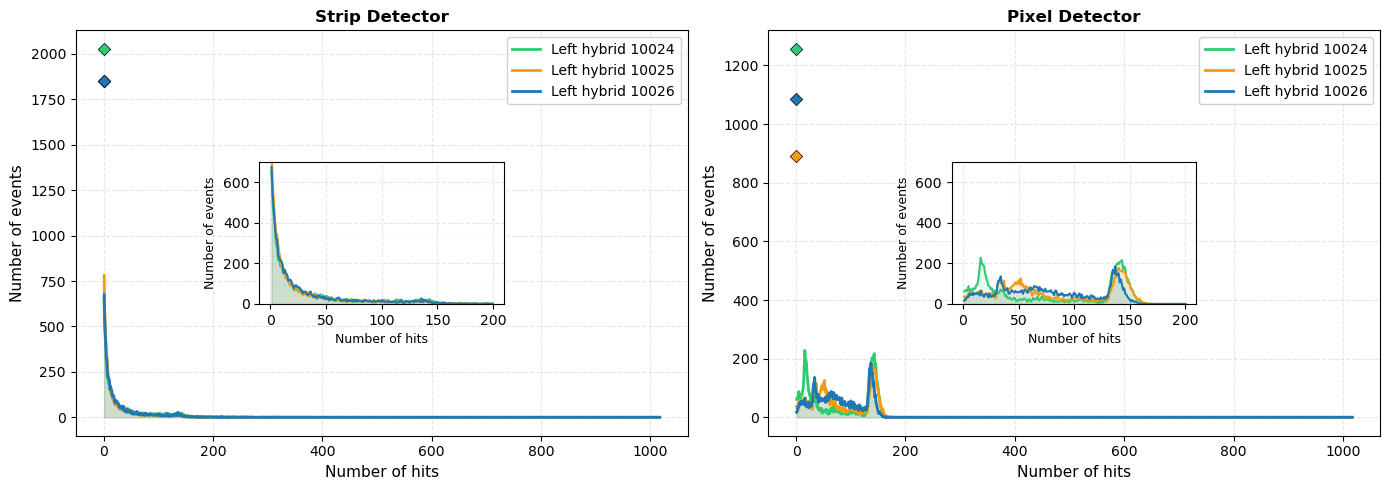

In [190]:
# Compute RMS statistics for common-mode noise and compare strip vs pixel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

hists = {

    'PS_10024_strip': Noise4bot1striphybrid,
    'PS_10024_pixel': Noise4bot1pixelhybrid,
    'PS_10025_strip': Noise5bot1striphybrid,
    'PS_10025_pixel': Noise5bot1pixelhybrid,
    'PS_10026_strip': Noise6bot1striphybrid,
    'PS_10026_pixel': Noise6bot1pixelhybrid,
}

rows = []
for name, h in hists.items():
    if h is None:
        print(f'{name}: histogram not found')
        continue
    entries = h.GetEntries()
    mean = h.GetMean()
    rms = h.GetRMS()
    rows.append({'hist': name, 'entries': entries, 'mean': mean, 'rms': rms})

df = pd.DataFrame(rows)
df['file'] = df['hist'].apply(lambda s: s.split('_')[1])
df['type'] = df['hist'].apply(lambda s: s.split('_')[2])
print(df)
print()

# Plot 2: Histogram distributions with zero-bin separation and inset zoom (0-200 CM)
colors = { '10024': '#2ecc71', '10025': '#f39c12', '10026': '#1f77b4'}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Store data for inset plotting
inset_data = {0: [], 1: []}  # {axis_index: [(centers, contents, color, file), ...]}

for i, t in enumerate(['strip', 'pixel']):
    for file in ['10024', '10025', '10026']:
        key = f'PS_{file}_{t}'
        h = hists.get(key)
        if h is None:
            continue
        nb = h.GetNbinsX()
        centers = np.array([h.GetBinCenter(b) for b in range(1, nb+1)], dtype=float)
        contents = np.array([h.GetBinContent(b) for b in range(1, nb+1)], dtype=float)
        
        # Separate exact-zero bin from the rest
        zero_mask = np.isclose(centers, 0.0)
        zero_count = float(contents[zero_mask].sum()) if np.any(zero_mask) else 0.0
        total_count = float(contents.sum())
        zero_fraction = (zero_count / total_count) if total_count > 0 else 0.0
        
        if zero_count > 0:
            print(f'Hybrid {file} {t}: exact-zero bin holds {zero_count:.0f} counts ({100.0 * zero_fraction:.1f}% of total entries)')
        
        # Plot non-zero distribution
        plot_centers = centers[~zero_mask]
        plot_contents = contents[~zero_mask]
        axes[i].plot(plot_centers, plot_contents, label=f'Left hybrid {file}', linewidth=2.0, color=colors[file])
        axes[i].fill_between(plot_centers, plot_contents, alpha=0.12, color=colors[file])
        
        # Mark zero bin separately
        if zero_count > 0:
            axes[i].scatter([0.0], [zero_count], color=colors[file], marker='D', s=40, zorder=5, edgecolors='black', linewidths=0.5)
        
        # Store data for inset (0-200 CM range)
        inset_data[i].append((centers, contents, colors[file], file))
    
    axes[i].set_xlabel('Number of hits', fontsize=11)
    axes[i].set_ylabel('Number of events', fontsize=11)
    axes[i].set_title(f'{t.capitalize()} Detector', fontsize=12, fontweight='bold')
    axes[i].legend(loc='upper right', fontsize=10, framealpha=0.9)
    axes[i].grid(True, alpha=0.3, linestyle='--')
    
    # Add inset for 0-200 CM range (positioned at center of plot)
    inset = inset_axes(axes[i], width='40%', height='35%', loc='center', borderpad=2.0)
    for centers, contents, color, file_label in inset_data[i]:
        # Filter to 0-200 CM range
        mask_inset = (centers >= 0) & (centers <= 200)
        inset_centers = centers[mask_inset]
        inset_contents = contents[mask_inset]
        
        # Separate zero bin in inset too
        zero_mask_inset = np.isclose(inset_centers, 0.0)
        plot_centers_inset = inset_centers[~zero_mask_inset]
        plot_contents_inset = inset_contents[~zero_mask_inset]
        
        inset.plot(plot_centers_inset, plot_contents_inset, linewidth=1.5, color=color)
        inset.fill_between(plot_centers_inset, plot_contents_inset, alpha=0.12, color=color)
        
        # Mark zero bin in inset
        if np.any(zero_mask_inset):
            zero_count_inset = float(inset_contents[zero_mask_inset].sum())
            if zero_count_inset > 0:
                inset.scatter([0.0], [zero_count_inset], color=color, marker='D', s=20, zorder=5, edgecolors='black', linewidths=0.5)
    
    inset.set_ylim(0, 700)
    inset.set_xlabel('Number of hits', fontsize=9)
    inset.set_ylabel('Number of events', fontsize=9)
    inset.grid(True, alpha=0.3, linestyle='--')
    inset.set_facecolor('white')
    inset.patch.set_alpha(0.9)

plt.tight_layout()
plt.show()

In [191]:
# #ANALYSIS OF HYBRID R CM NOISE

In [192]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers néceSSAires

inFile4bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ")
Noise4bot1striphybrid = inFile4bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseHitsStrip_OccupancyDriven_Hybrid(0)")
Noise4bot1pixelhybrid = inFile4bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_0/Hybrid_0/D_B(0)_O(0)_CommonNoiseHitsPixel_OccupancyDriven_Hybrid(0)")

inFile5bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise5bot1striphybrid = inFile5bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseHitsStrip_OccupancyDriven_Hybrid(2)")
Noise5bot1pixelhybrid = inFile5bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_1/Hybrid_2/D_B(0)_O(1)_CommonNoiseHitsPixel_OccupancyDriven_Hybrid(2)")

inFile6bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise6bot1striphybrid = inFile6bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_7/Hybrid_14/D_B(0)_O(7)_CommonNoiseHitsStrip_OccupancyDriven_Hybrid(14)")
Noise6bot1pixelhybrid = inFile6bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_7/Hybrid_14/D_B(0)_O(7)_CommonNoiseHitsPixel_OccupancyDriven_Hybrid(14)")


             hist  entries     mean        rms   file   type
0  PS_10024_strip   1017.0  31.2057  37.256538  10024  strip
1  PS_10024_pixel   1017.0  65.4201  58.075544  10024  pixel
2  PS_10025_strip   1017.0  40.7959  37.160011  10025  strip
3  PS_10025_pixel   1017.0  57.2618  50.497907  10025  pixel
4  PS_10026_strip   1017.0  33.0726  35.276467  10026  strip
5  PS_10026_pixel   1017.0  62.5509  46.935040  10026  pixel

Hybrid 10024 strip: exact-zero bin holds 1625 counts (16.2% of total entries)
Hybrid 10025 strip: exact-zero bin holds 1169 counts (11.7% of total entries)
Hybrid 10026 strip: exact-zero bin holds 1113 counts (11.1% of total entries)
Hybrid 10024 pixel: exact-zero bin holds 1392 counts (13.9% of total entries)
Hybrid 10025 pixel: exact-zero bin holds 1109 counts (11.1% of total entries)
Hybrid 10026 pixel: exact-zero bin holds 871 counts (8.7% of total entries)


/tmp/ipykernel_1625/1516452489.py:107: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0002_fig1.pdf


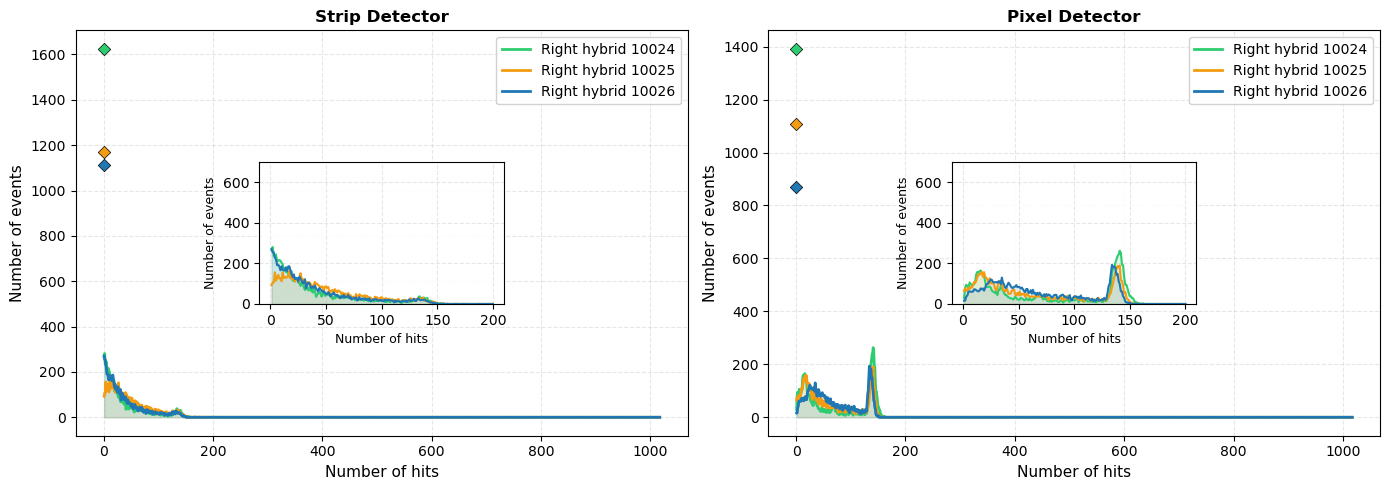

In [193]:
# Compute RMS statistics for common-mode noise and compare strip vs pixel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

hists = {

    'PS_10024_strip': Noise4bot1striphybrid,
    'PS_10024_pixel': Noise4bot1pixelhybrid,
    'PS_10025_strip': Noise5bot1striphybrid,
    'PS_10025_pixel': Noise5bot1pixelhybrid,
    'PS_10026_strip': Noise6bot1striphybrid,
    'PS_10026_pixel': Noise6bot1pixelhybrid,
}

rows = []
for name, h in hists.items():
    if h is None:
        print(f'{name}: histogram not found')
        continue
    entries = h.GetEntries()
    mean = h.GetMean()
    rms = h.GetRMS()
    rows.append({'hist': name, 'entries': entries, 'mean': mean, 'rms': rms})

df = pd.DataFrame(rows)
df['file'] = df['hist'].apply(lambda s: s.split('_')[1])
df['type'] = df['hist'].apply(lambda s: s.split('_')[2])
print(df)
print()

# Plot 2: Histogram distributions with zero-bin separation and inset zoom (0-200 CM)
colors = { '10024': '#2ecc71', '10025': '#f39c12', '10026': '#1f77b4'}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Store data for inset plotting
inset_data = {0: [], 1: []}  # {axis_index: [(centers, contents, color, file), ...]}

for i, t in enumerate(['strip', 'pixel']):
    for file in ['10024', '10025', '10026']:
        key = f'PS_{file}_{t}'
        h = hists.get(key)
        if h is None:
            continue
        nb = h.GetNbinsX()
        centers = np.array([h.GetBinCenter(b) for b in range(1, nb+1)], dtype=float)
        contents = np.array([h.GetBinContent(b) for b in range(1, nb+1)], dtype=float)
        
        # Separate exact-zero bin from the rest
        zero_mask = np.isclose(centers, 0.0)
        zero_count = float(contents[zero_mask].sum()) if np.any(zero_mask) else 0.0
        total_count = float(contents.sum())
        zero_fraction = (zero_count / total_count) if total_count > 0 else 0.0
        
        if zero_count > 0:
            print(f'Hybrid {file} {t}: exact-zero bin holds {zero_count:.0f} counts ({100.0 * zero_fraction:.1f}% of total entries)')
        
        # Plot non-zero distribution
        plot_centers = centers[~zero_mask]
        plot_contents = contents[~zero_mask]
        axes[i].plot(plot_centers, plot_contents, label=f'Right hybrid {file}', linewidth=2.0, color=colors[file])
        axes[i].fill_between(plot_centers, plot_contents, alpha=0.12, color=colors[file])
        
        # Mark zero bin separately
        if zero_count > 0:
            axes[i].scatter([0.0], [zero_count], color=colors[file], marker='D', s=40, zorder=5, edgecolors='black', linewidths=0.5)
        
        # Store data for inset (0-200 CM range)
        inset_data[i].append((centers, contents, colors[file], file))
    
    axes[i].set_xlabel('Number of hits', fontsize=11)
    axes[i].set_ylabel('Number of events', fontsize=11)
    axes[i].set_title(f'{t.capitalize()} Detector', fontsize=12, fontweight='bold')
    axes[i].legend(loc='upper right', fontsize=10, framealpha=0.9)
    axes[i].grid(True, alpha=0.3, linestyle='--')
    
    # Add inset for 0-200 CM range (positioned at center of plot)
    inset = inset_axes(axes[i], width='40%', height='35%', loc='center', borderpad=2.0)
    for centers, contents, color, file_label in inset_data[i]:
        # Filter to 0-200 CM range
        mask_inset = (centers >= 0) & (centers <= 200)
        inset_centers = centers[mask_inset]
        inset_contents = contents[mask_inset]
        
        # Separate zero bin in inset too
        zero_mask_inset = np.isclose(inset_centers, 0.0)
        plot_centers_inset = inset_centers[~zero_mask_inset]
        plot_contents_inset = inset_contents[~zero_mask_inset]
        
        inset.plot(plot_centers_inset, plot_contents_inset, linewidth=1.5, color=color)
        inset.fill_between(plot_centers_inset, plot_contents_inset, alpha=0.12, color=color)
        
        # Mark zero bin in inset
        if np.any(zero_mask_inset):
            zero_count_inset = float(inset_contents[zero_mask_inset].sum())
            if zero_count_inset > 0:
                inset.scatter([0.0], [zero_count_inset], color=color, marker='D', s=20, zorder=5, edgecolors='black', linewidths=0.5)
    
    inset.set_ylim(0, 700)
    inset.set_xlabel('Number of hits', fontsize=9)
    inset.set_ylabel('Number of events', fontsize=9)
    inset.grid(True, alpha=0.3, linestyle='--')
    inset.set_facecolor('white')
    inset.patch.set_alpha(0.9)

plt.tight_layout()
plt.show()

In [194]:
#ANALYSIS OF MODULE LEVEL CM NOISE

In [195]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir seulement les fichiers néceSSAires

inFile4bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ")
Noise4bot1strip = inFile4bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_0/D_B(0)_CommonNoiseHitsStrip_OccupancyDriven_OpticalGroup(0)")
Noise4bot1pixel = inFile4bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_0/D_B(0)_CommonNoiseHitsPixel_OccupancyDriven_OpticalGroup(0)")

inFile5bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise5bot1strip = inFile5bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_1/D_B(0)_CommonNoiseHitsStrip_OccupancyDriven_OpticalGroup(1)")
Noise5bot1pixel = inFile5bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_1/D_B(0)_CommonNoiseHitsPixel_OccupancyDriven_OpticalGroup(1)")

inFile6bot1 = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise6bot1strip = inFile6bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_7/D_B(0)_CommonNoiseHitsStrip_OccupancyDriven_OpticalGroup(7)")
Noise6bot1pixel = inFile6bot1.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_7/D_B(0)_CommonNoiseHitsPixel_OccupancyDriven_OpticalGroup(7)")


             hist  entries      mean        rms   file   type
0  PS_10024_strip   2033.0   59.6331  47.622974  10024  strip
1  PS_10024_pixel   2033.0  135.7570  52.980726  10024  pixel
2  PS_10025_strip   2033.0   63.5340  42.526801  10025  strip
3  PS_10025_pixel   2033.0  131.6770  53.015812  10025  pixel
4  PS_10026_strip   2033.0   58.5518  42.864395  10026  strip
5  PS_10026_pixel   2033.0  132.9928  52.382630  10026  pixel
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0003_fig1.pdf


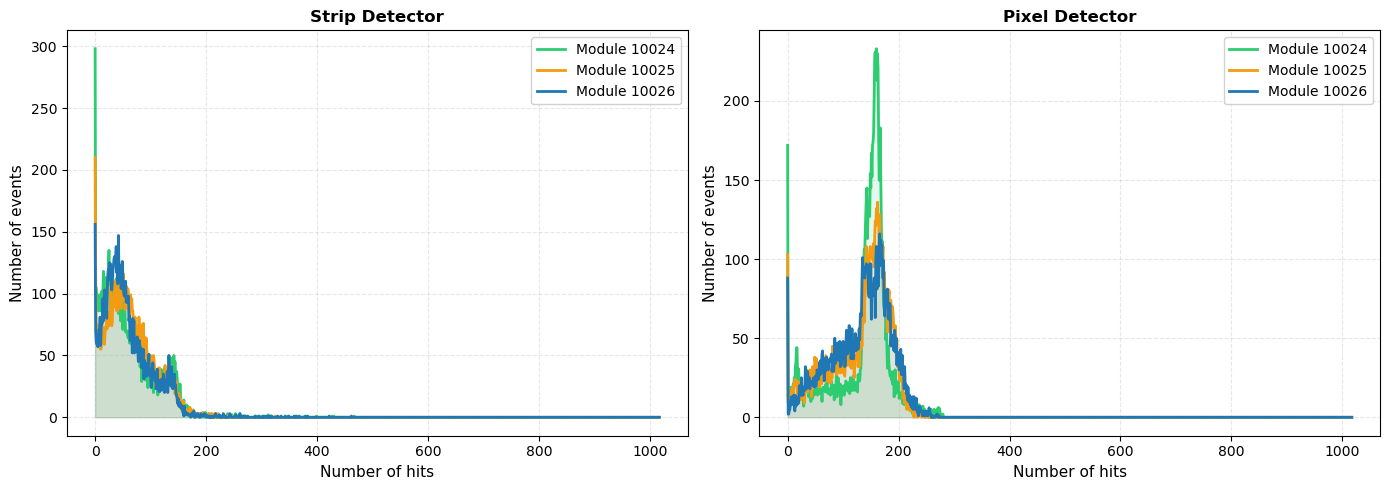

In [196]:
# Compute RMS statistics for common-mode noise and compare strip vs pixel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

hists = {
    'PS_10024_strip': Noise4bot1strip,
    'PS_10024_pixel': Noise4bot1pixel,
    'PS_10025_strip': Noise5bot1strip,
    'PS_10025_pixel': Noise5bot1pixel,
    'PS_10026_strip': Noise6bot1strip,
    'PS_10026_pixel': Noise6bot1pixel,
}

rows = []
for name, h in hists.items():
    if h is None:
        print(f'{name}: histogram not found')
        continue
    entries = h.GetEntries()
    mean = h.GetMean()
    rms = h.GetRMS()
    rows.append({'hist': name, 'entries': entries, 'mean': mean, 'rms': rms})

df = pd.DataFrame(rows)
df['file'] = df['hist'].apply(lambda s: s.split('_')[1])
df['type'] = df['hist'].apply(lambda s: s.split('_')[2])
print(df)

# Plot 2: Histogram distributions (counts) with improved aesthetics — do NOT normalize counts
colors = {'10024': '#2ecc71', '10025': '#f39c12', '10026': '#1f77b4'}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, t in enumerate(['strip', 'pixel']):
    for file in ['10024', '10025', '10026']:
        key = f'PS_{file}_{t}'
        h = hists.get(key)
        if h is None:
            continue
        nb = h.GetNbinsX()
        centers = [h.GetBinCenter(b) for b in range(1, nb+1)]
        contents = np.array([h.GetBinContent(b) for b in range(1, nb+1)])
        # Do not normalize; plot raw counts
        axes[i].plot(centers, contents, label=f'Module {file}', linewidth=2.0, color=colors[file])
        axes[i].fill_between(centers, contents, alpha=0.12, color=colors[file])
    
    axes[i].set_xlabel('Number of hits', fontsize=11)
    axes[i].set_ylabel('Number of events', fontsize=11)
    axes[i].set_title(f'{t.capitalize()} Detector', fontsize=12, fontweight='bold')
    axes[i].legend(loc='upper right', fontsize=10, framealpha=0.9)
    axes[i].grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

In [197]:
# 3sigma plots for all STRIP detectors of PS modules (10024, 10025, 10026) for burn-in AND DEE

In [198]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt 

# Ouvrir seulement les fichiers néceSSAires
inFile2bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise2bot1mod = inFile2bot1mod.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_0/D_B(0)_CommonNoiseHitsStrip_SigmaNoise_3.00_OpticalGroup(0)")

inFile2bot1modprime = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/Dee PS.root","READ") 
Noise2bot1modprime = inFile2bot1modprime.Get("Detector/Board_0/OpticalGroup_0/D_B(0)_CommonNoiseHitsStrip_SigmaNoise_3.00_OpticalGroup(0)")

inFile3bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ") 
Noise3bot1mod = inFile3bot1mod.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_1/D_B(0)_CommonNoiseHitsStrip_SigmaNoise_3.00_OpticalGroup(1)")

inFile3bot1modprime = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/Dee PS.root","READ") 
Noise3bot1modprime = inFile3bot1modprime.Get("Detector/Board_0/OpticalGroup_1/D_B(0)_CommonNoiseHitsStrip_SigmaNoise_3.00_OpticalGroup(1)")

inFile4bot1mod = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root","READ")
Noise4bot1mod = inFile4bot1mod.Get("Iteration_13_PSfullTest_2026-03-01_01-50-58/Detector/Board_0/OpticalGroup_7/D_B(0)_CommonNoiseHitsStrip_SigmaNoise_3.00_OpticalGroup(7)")

inFile5bot1modprime = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/Dee PS.root","READ") 
Noise5bot1modprime = inFile5bot1modprime.Get("Detector/Board_0/OpticalGroup_3/D_B(0)_CommonNoiseHitsStrip_SigmaNoise_3.00_OpticalGroup(3)")

In [199]:
# Extract bin-by-bin data from the five 2S hybrid histograms
module_histograms = [
    ("Module 10024 (burn-in)", Noise2bot1mod),
    ("Module 10024 (DEE)", Noise2bot1modprime),
    ("Module 10026", Noise4bot1mod),
    ("Module 10025 (burn-in)", Noise3bot1mod),
    ("Module 10025 (DEE)", Noise3bot1modprime),
    ("Module 10011", Noise5bot1modprime)
]

histogram_data = {}

print("\n" + "=" * 80)
print("HISTOGRAM BIN-BY-BIN DATA EXTRACTION")
print("=" * 80)

for module_name, hist in module_histograms:
    if hist is None:
        print(f"\n[SKIP] {module_name}: histogram not found")
        continue
    
    # Extract basic statistics
    entries = int(hist.GetEntries())
    mean = float(hist.GetMean())
    std_dev = float(hist.GetStdDev())
    rms = float(hist.GetRMS())
    
    print(f"\n{module_name}:")
    print(f"  Entries: {entries}")
    print(f"  Mean: {mean:.4f}")
    print(f"  Std Dev: {std_dev:.4f}")
    print(f"  RMS: {rms:.4f}")
    
    # Extract bin-by-bin data
    # ROOT histograms are 1-indexed (bin 0 is underflow, bin N+1 is overflow)
    bin_centers = []
    bin_contents = []
    
    for i in range(1, hist.GetNbinsX() + 1):
        bin_centers.append(hist.GetXaxis().GetBinCenter(i))
        bin_contents.append(hist.GetBinContent(i))
    
    histogram_data[module_name] = {
        "entries": entries,
        "mean": mean,
        "std_dev": std_dev,
        "rms": rms,
        "bin_centers": np.array(bin_centers),
        "bin_contents": np.array(bin_contents),
        "histogram": hist,
    }


HISTOGRAM BIN-BY-BIN DATA EXTRACTION

Module 10024 (burn-in):
  Entries: 2033
  Mean: 4.5551
  Std Dev: 10.6199
  RMS: 10.6199

Module 10024 (DEE):
  Entries: 2033
  Mean: 4.2086
  Std Dev: 9.4167
  RMS: 9.4167

Module 10026:
  Entries: 2033
  Mean: 3.8074
  Std Dev: 9.1487
  RMS: 9.1487

Module 10025 (burn-in):
  Entries: 2033
  Mean: 3.5037
  Std Dev: 7.6616
  RMS: 7.6616

Module 10025 (DEE):
  Entries: 2033
  Mean: 3.5406
  Std Dev: 5.1604
  RMS: 5.1604

Module 10011:
  Entries: 2033
  Mean: 3.5205
  Std Dev: 8.0006
  RMS: 8.0006


In [200]:
# Add Gaussian fits to each histogram on the canvas
import ROOT
import numpy as np
from scipy.stats import norm

# Threshold used by the "SigmaNoise_3.00" histograms below -- keep this in sync with that name.
n_sigma_threshold = 3.0

print("\n" + "=" * 80)
print("ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS")
print("=" * 80)

# Create a new canvas with fits
canvas_fit = ROOT.TCanvas("hybrids_sigma3_with_fits", "Hybrid Common-Mode Noise with Fits (3σ threshold)",1200,400 * rw)
canvas_fit.Divide(cols, rw)

fit_results_canvas = {}
colors_fit = [ROOT.kBlue, ROOT.kRed, ROOT.kGreen+2, ROOT.kMagenta, ROOT.kCyan, 
              ROOT.kOrange+7, ROOT.kYellow+2, ROOT.kSpring+9]

# Keep the fit order aligned with the histogram_data built in this cell
hybrid_names = list(histogram_data.keys())

for i, hybrid_name in enumerate(hybrid_names):
    pad_num = i + 1
    canvas_fit.cd(pad_num)
    ROOT.gPad.SetLeftMargin(0.12)
    ROOT.gPad.SetBottomMargin(0.12)
    ROOT.gPad.SetGrid()
    ROOT.gPad.SetLogy(1)
    
    hist_data = histogram_data.get(hybrid_name)
    if hist_data is None or hist_data["histogram"] is None:
        ROOT.TText(0.2, 0.5, f"No data for {hybrid_name}").Draw()
        continue
    
    hist = hist_data["histogram"]
    
    # Style the histogram
    hist.SetLineColor(colors_fit[i % len(colors_fit)])
    hist.SetLineWidth(2)
    hist.SetFillColor(colors_fit[i % len(colors_fit)])
    hist.SetFillStyle(3004)
    hist.SetTitle(hybrid_name)
    hist.GetXaxis().SetTitle("Number of hits (3σ above noise)")
    hist.GetXaxis().SetRangeUser(0.0, 160.0)
    hist.GetYaxis().SetTitle("Number of events")
    hist.GetXaxis().SetTitleSize(0.05)
    hist.GetYaxis().SetTitleSize(0.05)
    hist.GetXaxis().SetLabelSize(0.04)
    hist.GetYaxis().SetLabelSize(0.04)
    
    # Draw histogram
    hist.Draw("HIST")
    
    # Perform Gaussian fit
    x_min = float(hist.GetXaxis().GetXmin())
    x_max = float(hist.GetXaxis().GetXmax())
    
    # Find peak for initial guess
    peak_idx = hist.GetMaximumBin()
    peak_x = hist.GetXaxis().GetBinCenter(peak_idx)
    peak_y = hist.GetBinContent(peak_idx)
    
    # Create fit function
    safe_name = "".join(ch if ch.isalnum() else "_" for ch in f"fit_hybrids_{hybrid_name}")
    fit_func = ROOT.TF1(safe_name, "gaus", x_min, x_max)
    
    # Set initial parameters
    mean_guess = hist_data["mean"]
    std_guess = hist_data["std_dev"]
    amplitude_guess = max(peak_y, 1.0)
    
    fit_func.SetParameters(amplitude_guess, mean_guess, std_guess)
    fit_func.SetParLimits(0, 0.0, max(amplitude_guess * 10.0, 1.0))
    fit_func.SetParLimits(1, x_min, x_max)
    fit_func.SetParLimits(2, 1e-6, max(x_max - x_min, std_guess * 10.0))
    
    # Perform fit
    try:
        fit_result = hist.Fit(fit_func, "LQRS")
        fit_status = int(fit_result)
        
        amplitude_fit = float(fit_func.GetParameter(0))
        mean_fit = float(fit_func.GetParameter(1))
        std_fit = abs(float(fit_func.GetParameter(2)))
        
        # Get parameter errors
        amplitude_err = float(fit_func.GetParError(0))
        mean_err = float(fit_func.GetParError(1))
        std_err = abs(float(fit_func.GetParError(2)))
        
        fit_results_canvas[hybrid_name] = {
            "amplitude": amplitude_fit,
            "amplitude_err": amplitude_err,
            "mean": mean_fit,
            "mean_err": mean_err,
            "std": std_fit,
            "std_err": std_err,
            "status": fit_status,
            "fit_func": fit_func,
        }
        
        # Draw fit function in orange
        #fit_func.SetLineColor(ROOT.kOrange)
        #fit_func.SetLineWidth(2)
        #fit_func.SetLineStyle(7)  # dashed line
        #fit_func.Draw("SAME")
        
        # Fit and overlay a theoretical Poisson distribution for the no-CMN expectation
        # Cap the evaluation domain well below where TMath::Gamma(x+1) overflows to inf (~x>170);
        # a TF1 that hits NaN/Inf anywhere in its declared range fails to draw at all, even in the
        # (perfectly finite) low-x region actually visible on the plot.
        poisson_x_max = min(x_max, 100.0)
        poisson_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_hybrids_{hybrid_name}")
        poisson_func = ROOT.TF1(poisson_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
        poisson_func.SetNpx(500)
        poisson_norm_guess = max(float(hist.Integral()), 1.0)
        poisson_lambda_guess = max(mean_guess, 1e-6)
        poisson_func.SetParameter(0, poisson_norm_guess)
        poisson_func.FixParameter(0, poisson_norm_guess)
        poisson_func.SetParameter(1, poisson_lambda_guess)
        poisson_func.SetParLimits(1, 1e-6, max(x_max, poisson_lambda_guess * 10.0))
        
        try:
            poisson_result = hist.Fit(poisson_func, "LQRS")
            poisson_status = int(poisson_result)
            
            poisson_lambda_fit = float(poisson_func.GetParameter(1))
            poisson_lambda_err = float(poisson_func.GetParError(1))
            
            poisson_func.SetLineColor(ROOT.kBlack)
            poisson_func.SetLineWidth(2)
            #poisson_func.SetLineStyle(7)
            poisson_func.Draw("SAME")
            
            fit_results_canvas[hybrid_name]["poisson"] = {
                "norm": poisson_norm_guess,
                "norm_err": 0.0,
                "lambda": poisson_lambda_fit,
                "lambda_err": poisson_lambda_err,
                "status": poisson_status,
                "fit_func": poisson_func,
            }
            
            print(f"  Poisson Norm: {poisson_norm_guess:.4f} (fixed)")
            print(f"  Poisson Lambda: {poisson_lambda_fit:.4f} ± {poisson_lambda_err:.4f}")

            # Theoretical Poisson expectation with NO common-mode noise: if every strip's noise
            # were an independent Gaussian, the number of channels crossing a pure n_sigma_threshold
            # would be Poisson with lambda = n_channels * P(Z > n_sigma_threshold) (one-sided Gaussian
            # tail). Unlike poisson_func above, this lambda is NOT fit -- it's fixed from the physical
            # channel count and the threshold, so the gap to the data/fit shows the CMN excess.
            n_channels = int(hist.GetNbinsX()) - 1
            lambda_theory = n_channels * norm.sf(n_sigma_threshold)
            theory_name = "".join(ch if ch.isalnum() else "_" for ch in f"poisson_theory_hybrids_{hybrid_name}")
            theory_func = ROOT.TF1(theory_name, "[0] * TMath::Exp(-[1]) * TMath::Power([1], x) / TMath::Gamma(x + 1.0)", x_min, poisson_x_max)
            theory_func.SetNpx(500)
            theory_func.FixParameter(0, poisson_norm_guess)
            theory_func.FixParameter(1, lambda_theory)
            theory_func.SetLineColor(ROOT.kGray + 2)
            theory_func.SetLineWidth(2)
            theory_func.SetLineStyle(2)
            theory_func.Draw("SAME")

            fit_results_canvas[hybrid_name]["poisson_theory"] = {
                "n_channels": n_channels,
                "lambda": lambda_theory,
                "fit_func": theory_func,
            }

            print(f"  Poisson (theory, no CMN): n_channels={n_channels}, lambda={lambda_theory:.4f}")

            legend_fit = ROOT.TLegend(0.30, 0.72, 0.95, 0.92)
            legend_fit.AddEntry(hist, "Data (3σ hits)", "f")
            legend_fit.AddEntry(poisson_func, "Poisson fit (λ = data mean)", "l")
            legend_fit.AddEntry(theory_func, "Poisson theory, no CMN (λ = n·P(Z>3σ))", "l")
            legend_fit.SetTextSize(0.03)
            legend_fit.SetFillStyle(0)
            legend_fit.SetBorderSize(0)
            legend_fit.Draw()
        except Exception as e:
            print(f"  Poisson fit failed - {e}")
            fit_results_canvas[hybrid_name]["poisson"] = {"status": -1, "error": str(e)}
        
        # Add legend
        #legend = ROOT.TLegend(0.55, 0.7, 0.95, 0.95)
        #legend.AddEntry(hist, "Data", "f")
        #legend.AddEntry(fit_func, "Gaussian Fit", "l")
        #if fit_results_canvas[hybrid_name].get("poisson", {}).get("status", -1) >= 0:
        #    legend.AddEntry(poisson_func, "Poisson fit", "l")
        #legend.SetTextSize(0.04)
        #legend.SetFillStyle(0)
        #legend.Draw()
        
        # Print fit results with parameter errors
        print(f"\n{hybrid_name}:")
        print(f"  Fit Status: {fit_status}")
        print(f"  Amplitude: {amplitude_fit:.4f} ± {amplitude_err:.4f}")
        print(f"  Mean: {mean_fit:.4f} ± {mean_err:.4f}")
        print(f"  Std Dev: {std_fit:.4f} ± {std_err:.4f}")
        
    except Exception as e:
        print(f"\n{hybrid_name}: Fit failed - {e}")
        fit_results_canvas[hybrid_name] = {"status": -1, "error": str(e)}

# Hide empty pads
for i in range(len(hybrid_names), rw * cols):
    canvas_fit.cd(i + 1)
    ROOT.gPad.Draw()

canvas_fit.Update()
canvas_fit.Draw()

print("\n" + "=" * 80)
print("FITTING COMPLETE")
print("=" * 80)



ADDING GAUSSIAN FITS TO EACH HISTOGRAM ON CANVAS
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 4.3097 ± 0.0208
  Poisson (theory, no CMN): n_channels=1017, lambda=1.3728

Module 10024 (burn-in):
  Fit Status: 0
  Amplitude: 678.3713 ± 8.3093
  Mean: -0.5000 ± 0.0016
  Std Dev: 11.7618 ± 0.0832
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 3.9666 ± 0.0199
  Poisson (theory, no CMN): n_channels=1017, lambda=1.3728

Module 10024 (DEE):
  Fit Status: 0
  Amplitude: 757.8444 ± 9.2827
  Mean: -0.5000 ± 0.0015
  Std Dev: 10.5284 ± 0.0745
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 3.6697 ± 0.0192
  Poisson (theory, no CMN): n_channels=1017, lambda=1.3728

Module 10026:
  Fit Status: 0
  Amplitude: 789.0462 ± 9.6649
  Mean: -0.5000 ± 0.0014
  Std Dev: 10.1120 ± 0.0715
  Poisson Norm: 10000.0000 (fixed)
  Poisson Lambda: 3.4374 ± 0.0185
  Poisson (theory, no CMN): n_channels=1017, lambda=1.3728

Module 10025 (burn-in):
  Fit Status: 0
  Amplitude: 922.9805 ± 11.3053
  Me

Warning in <TCanvas::Constructor>: Deleting canvas with same name: hybrids_sigma3_with_fits


In [201]:
# Comparaison of the tail of the distribution of strip sensor of PS modules (10024,1025) for burn in AND DEE 

In [202]:
pois_burn = fit_results_canvas["Module 10024 (burn-in)"]["poisson"]["fit_func"]
pois_dee  = fit_results_canvas["Module 10024 (DEE)"]["poisson"]["fit_func"]

print("Burn-in λ =", pois_burn.GetParameter(1))
print("DEE     λ =", pois_dee.GetParameter(1))

Burn-in λ = 4.309666417574498
DEE     λ = 3.9665859914416264


In [203]:
c_compare = ROOT.TCanvas("c_compare", "Module 10024: burn-in vs DEE",900,600)
c_compare.SetLogy()

h_burnin = Noise2bot1mod
h_dee    = Noise2bot1modprime

# Draw histogram
h_burnin.SetLineColor(ROOT.kBlue)
h_burnin.Draw("HIST")

# DEE histogram
h_dee.SetLineColor(ROOT.kRed)
h_dee.Draw("HIST SAME")

# Common axis range
xmax = max(
    h_burnin.GetXaxis().GetXmax(),
    h_dee.GetXaxis().GetXmax()
)

h_burnin.GetXaxis().SetRangeUser(0, 200)
h_burnin.SetTitle("Module 10024: Burn-in vs DEE")
h_burnin.GetXaxis().SetTitle("Number of hits (3#sigma above noise)")
h_burnin.GetYaxis().SetTitle("Events")

h_burnin.SetFillStyle(0)
h_dee.SetFillStyle(0)

h_burnin.GetListOfFunctions().Clear()
h_dee.GetListOfFunctions().Clear()

h_burnin.SetStats(0)
h_dee.SetStats(0)

h_burnin.Draw("HIST")
h_dee.Draw("HIST SAME")

pois_burn.SetLineColor(ROOT.kAzure+10)
pois_burn.SetLineWidth(3)
pois_burn.SetLineStyle(2)
pois_burn.Draw("SAME")

pois_dee.SetLineColor(ROOT.kMagenta+2)
pois_dee.SetLineWidth(3)
pois_dee.SetLineStyle(2)
pois_dee.Draw("SAME")

leg = ROOT.TLegend(0.65,0.75,0.88,0.88)
leg.AddEntry(h_burnin, "Burn-in data", "l")
leg.AddEntry(pois_burn, "Burn-in poisson fit", "l")
leg.AddEntry(h_dee, "DEE data", "l")
leg.AddEntry(pois_dee, "DEE poisson fit", "l")
# 1. Make the background transparent so it doesn't block your histogram
leg.SetFillStyle(0) 
# 2. Remove the heavy black border box
leg.SetBorderSize(0) 
# 3. Use ROOT's standard high-quality scalable font (Font 42)
leg.SetTextFont(42) 
# Your existing text size (0.04 is usually a great choice)
leg.SetTextSize(0.04) 
leg.Draw()

c_compare.Update()
c_compare.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_compare


In [204]:
pois_burn = fit_results_canvas["Module 10025 (burn-in)"]["poisson"]["fit_func"]
pois_dee  = fit_results_canvas["Module 10025 (DEE)"]["poisson"]["fit_func"]

print("Burn-in λ =", pois_burn.GetParameter(1))
print("DEE     λ =", pois_dee.GetParameter(1))

Burn-in λ = 3.437364036679563
DEE     λ = 3.5291481886974023


In [205]:
c_compare = ROOT.TCanvas("c_compare", "Module 10025: burn-in vs DEE",900,600)
c_compare.SetLogy()

h_burnin = Noise3bot1mod
h_dee    = Noise3bot1modprime

# Draw histogram
h_burnin.SetLineColor(ROOT.kBlue)
h_burnin.Draw("HIST")

# DEE histogram
h_dee.SetLineColor(ROOT.kRed)
h_dee.Draw("HIST SAME")

# Common axis range
xmax = max(
    h_burnin.GetXaxis().GetXmax(),
    h_dee.GetXaxis().GetXmax()
)

h_burnin.GetXaxis().SetRangeUser(0, 200)
h_burnin.SetTitle("Module 10025: Burn-in vs DEE")
h_burnin.GetXaxis().SetTitle("Number of hits (3#sigma above noise)")
h_burnin.GetYaxis().SetTitle("Events")

h_burnin.SetFillStyle(0)
h_dee.SetFillStyle(0)

h_burnin.GetListOfFunctions().Clear()
h_dee.GetListOfFunctions().Clear()

h_burnin.SetStats(0)
h_dee.SetStats(0)

h_burnin.Draw("HIST")
h_dee.Draw("HIST SAME")

pois_burn.SetLineColor(ROOT.kAzure+10)
pois_burn.SetLineWidth(3)
pois_burn.SetLineStyle(2)
pois_burn.Draw("SAME")

pois_dee.SetLineColor(ROOT.kMagenta+2)
pois_dee.SetLineWidth(3)
pois_dee.SetLineStyle(2)
pois_dee.Draw("SAME")

leg = ROOT.TLegend(0.65,0.75,0.88,0.88)
leg.AddEntry(h_burnin, "Burn-in data", "l")
leg.AddEntry(pois_burn, "Burn-in poisson fit", "l")
leg.AddEntry(h_dee, "DEE data", "l")
leg.AddEntry(pois_dee, "DEE poisson fit", "l")
# 1. Make the background transparent so it doesn't block your histogram
leg.SetFillStyle(0) 
# 2. Remove the heavy black border box
leg.SetBorderSize(0) 
# 3. Use ROOT's standard high-quality scalable font (Font 42)
leg.SetTextFont(42) 
# Your existing text size (0.04 is usually a great choice)
leg.SetTextSize(0.04) 
leg.Draw()

c_compare.Update()
c_compare.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_compare


In [206]:
#STUDY OF 3σ OCCUPANCY: toy model with/without Common Mode Noise for STRIP sensors of PS module

In [2]:
# Toy model for hits-per-event occupancy at a chosen n-sigma threshold, with an optional
# common-mode noise (CMN) component: a single Gaussian shared by all strips covered by the
# fitted level (SSA/hybrid/module) in a given (toy) event, added on top of each strip's own
# uncorrelated Gaussian noise.

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, minimize

ITERATION_PS = "Iteration_13_PSfullTest_2026-03-01_01-50-58"


def extract_SSA_noise_and_hits(root_file, og_name, hybrid_name, hybrid_id, SSA_id,
                                n_sigma=3.0, iteration=ITERATION_PS):
    """Pull per-strip noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one SSA."""
    
    base = f"{iteration}/Detector/Board_0/{og_name}/{hybrid_name}/SSA_{SSA_id}/D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_"
    strip_hist = root_file.Get(base + f"ChannelNoise_Chip({SSA_id})")
    hits_hist = root_file.Get(base + f"CommonNoiseHits_SigmaNoise_{n_sigma:.2f}_Chip({SSA_id})")
    if not strip_hist or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}/{hybrid_name}/SSA_{SSA_id} at {n_sigma}sigma")
    sigma_i = np.array([strip_hist.GetBinContent(int(i)) for i in range(1, strip_hist.GetNbinsX() + 1)])
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins


def extract_hybrid_noise_and_hits(root_file, og_name, hybrid_name, hybrid_id, n_sigma=3.0, iteration=ITERATION_PS):
                                
    """Pull per-strip noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one hybrid."""
    
    base = f"{iteration}/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_"
    strip_hist = root_file.Get(base+ f"StripChannelNoise_Hybrid({hybrid_id})")
    hits_hist = root_file.Get(base + f"CommonNoiseHitsStrip_SigmaNoise_{n_sigma:.2f}_Hybrid({hybrid_id})")
    if not strip_hist or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}/{hybrid_name} at {n_sigma}sigma")
    sigma_i = np.array([strip_hist.GetBinContent(int(i)) for i in range(1, strip_hist.GetNbinsX() + 1)])
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins

def extract_module_noise_and_hits(root_file, og_name, og_id, n_sigma=3.0, iteration=ITERATION_PS):
                                
    """Pull per-strip noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one module (both
    hybrids' strip channels concatenated)."""
    
    base = f"{iteration}/Detector/Board_0/{og_name}/D_B(0)_"
    # A module is the two hybrids sharing this optical group: Hybrid_(2*module_id) and
    # Hybrid_(2*module_id + 1). Combine their StripChannelNoise histograms into one sample
    # (all strips of both hybrids together) rather than picking just one hybrid.
    module_id = int(og_name.split("_")[-1])
    strip_hist = np.concatenate([
        np.array([hist.GetBinContent(int(i)) for i in range(1, hist.GetNbinsX() + 1)])
        for hist in (
            root_file.Get(
                f"{iteration}/Detector/Board_0/{og_name}/Hybrid_{hid}/"
                f"D_B(0)_O({hid // 2})_StripChannelNoise_Hybrid({hid})"
            )
            for hid in (2 * module_id, 2 * module_id + 1)
        )
    ])
    hits_hist = root_file.Get(base + f"CommonNoiseHitsStrip_SigmaNoise_{n_sigma:.2f}_OpticalGroup({og_id})")
    if strip_hist.size == 0 or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}at {n_sigma}sigma")
    sigma_i = strip_hist
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins

def simulate_hits(sigma_i, n_sigma, uncorr_std, cm_base, sigma_cm=0.0, k_thresh=1.0):
    """uncorr_std: (n_toy, n_strips) standard-normal draws (one per strip, reused across calls).
    cm_base: (n_toy,) standard-normal draws, one common value per event (reused across calls).
    Reusing the same underlying random draws for every sigma_cm value (common random numbers)
    keeps the mean/std of the simulated distribution a smooth, deterministic function of sigma_cm,
    which is what makes the fit below well-behaved.
    k_thresh: multiplicative correction to the nominal n_sigma threshold (default 1.0, i.e. no
    correction applied). See fit_common_mode_and_threshold for why this is needed."""

    threshold_i = (k_thresh * n_sigma) * sigma_i
    total = uncorr_std * sigma_i[None, :] + (cm_base * sigma_cm)[:, None]
    return (total > threshold_i[None, :]).sum(axis=1)

def fit_common_mode_and_threshold(sigma_i, n_sigma, real_bins, uncorr_std, cm_base,
                                   k_thresh_range=(1.0, 1.4), sigma_cm_max=None,
                                   n_grid_k=11, n_grid_sigma=21, max_bin=None):
    """Find the CMN width sigma_cm whose simulated hit-count histogram matches the real PS module
        data bin-by-bin, minimizing a Pearson chi-square: sum((observed - expected)^2 / expected) over
        hit-count bins 0..max_bin-1 plus a trailing overflow bin, where 'expected' is the toy model's
        bin counts rescaled to the real data's total event count. Unlike KS (which only tracks the single
        worst-case CDF gap and can ignore how badly the tail is reproduced) or matching mean+std (two
        summary numbers), this scores every bin, so a toy tail the data doesn't support gets penalized
        directly through the overflow bin.
    Jointly fits an effective per-strip threshold scale k_thresh (applied as
    threshold_i = k_thresh * n_sigma * sigma_i) together with the common-mode noise width
    sigma_cm, using the same Pearson chi-square objective as fit_common_mode_sigma.

    Why this is needed: even with sigma_cm=0 (no common-mode noise at all), the nominal n_sigma
    threshold alone already over-predicts how often strips cross threshold from uncorrelated noise
    -- e.g. for a 960-strip PS hybrid at n_sigma=3.0, pure per-strip Gaussian noise gives
    P(hits=0) ~= 27%, while the real PS module data show 42-75% across all 6 hybrids. sigma_cm
    alone cannot close this gap: adding common-mode variance only ever pushes P(hits=0) further
    down, never up (confirmed empirically -- both a heavy-tailed Student's-t common-mode term and
    a discrete Gaussian+Poisson burst mixture made the fit worse, not better, because their
    "quiet" baseline was still this same over-spread mechanism). Fitting k_thresh alongside
    sigma_cm corrects that baseline first, so sigma_cm is left to explain only the genuine
    common-mode spread (and L/R asymmetry) on top of it.

    A coarse grid search over (k_thresh, sigma_cm) seeds a local Nelder-Mead refinement, the same
    two-stage approach used by fit_common_mode_sigma's 1-D scan, for robustness against the
    objective's local wiggles from finite-N_TOY sampling noise."""

    n_events_real = float(real_bins.sum())
    if max_bin is None:
        nonzero = np.nonzero(real_bins)[0]
        max_bin = min(int(nonzero.max()) + 10, len(real_bins) - 1) if nonzero.size > 0 else len(real_bins) - 1
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    n_events_toy = uncorr_std.shape[0]
    hi_sigma = sigma_cm_max if sigma_cm_max is not None else sigma_i.mean() * 2.0

    def chi2_obj(params):
        k_thresh, sigma_cm = params
        hits = simulate_hits(sigma_i, n_sigma, uncorr_std, cm_base, sigma_cm, k_thresh=k_thresh)
        toy_counts = np.array([np.sum(hits == k) for k in range(max_bin)] + [np.sum(hits >= max_bin)])
        expected = toy_counts * (n_events_real / n_events_toy)
        mask = expected > 0
        return float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))

    k_grid = np.linspace(k_thresh_range[0], k_thresh_range[1], n_grid_k)
    sigma_cm_grid = np.linspace(0.0, hi_sigma, n_grid_sigma)
    best = (np.inf, (k_grid[0], sigma_cm_grid[0]))
    for k in k_grid:
        for sc in sigma_cm_grid:
            chi2 = chi2_obj((k, sc))
            if chi2 < best[0]:
                best = (chi2, (k, sc))

    res = minimize(chi2_obj, x0=list(best[1]), method="Nelder-Mead",
                    options={"xatol": 1e-4, "fatol": 1e-2, "maxiter": 500})
    k_thresh_best, sigma_cm_best = float(res.x[0]), float(res.x[1])

    # 1-D chi-square scan at the best-fit k_thresh, matching fit_common_mode_sigma's output shape
    # so the diagnostic plot below (chi-square and mean/std ratios vs sigma_cm) still works.
    cm_scan = np.linspace(0.0, hi_sigma, 50)
    cm_scan_obj = np.array([chi2_obj((k_thresh_best, sc)) for sc in cm_scan])
    return k_thresh_best, sigma_cm_best, cm_scan, cm_scan_obj

def plot_toy_vs_data(toy_hits, real_bins, n_sigma, hybrid_label, cbc_label,
                      subtitle, save_path=None, max_bin=None):
    n_events_toy = len(toy_hits)
    n_events_real = int(round(real_bins.sum()))

    if max_bin is None:
        max_bin = min(max(int(np.nonzero(real_bins)[0].max()) + 1, int(toy_hits.max()) + 1) + 3, 50)

    toy_counts = np.array([np.sum(toy_hits == k) for k in range(max_bin)] + [np.sum(toy_hits >= max_bin)])
    real_trunc = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))
    toy_mean, toy_std = float(toy_hits.mean()), float(toy_hits.std())

    x = np.arange(max_bin + 1)
    toy_pmf, real_pmf = toy_counts / n_events_toy, real_trunc / n_events_real
    toy_err, real_err = np.sqrt(toy_counts) / n_events_toy, np.sqrt(real_trunc) / n_events_real

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.errorbar(x, toy_pmf, yerr=toy_err, fmt="+", color="tab:blue", label="Toy model simulation", markersize=6)
    ax.errorbar(x, real_pmf, yerr=real_err, fmt="+", color="tab:red", label="2S module data", markersize=6)
    ax.set_xlabel("Number of Hits", fontsize=16)
    ax.set_ylabel("Rate of events (log scale)", fontsize=16)
    ax.set_title(f"{n_sigma:.0f}$\\sigma$ Noise Threshold, {hybrid_label} {cbc_label}", fontsize=16, fontweight="bold", loc="left")
    ax.text(0.2, 0.98, subtitle, transform=ax.transAxes, fontstyle="italic", fontsize=11, va="top")
    ax.set_xlim(-0.5, max_bin + 0.5)
    ax.set_yscale("log")
    nonzero_pmf = np.concatenate([toy_pmf[toy_pmf > 0], real_pmf[real_pmf > 0]])
    if nonzero_pmf.size > 0:
        ax.set_ylim(bottom=nonzero_pmf.min() * 0.5)
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=14)

    stats_text = (
        f"Toy Model Simulation\n"
        f"  Events   {n_events_toy:,}\n"
        f"  $\\mu$        {toy_mean:.3f}\n"
        f"  $\\sigma$        {toy_std:.3f}\n\n"
        f"2S Module Data\n"
        f"  Events   {n_events_real:,}\n"
        f"  $\\mu$        {real_mean:.3f}\n"
        f"  $\\sigma$        {real_std:.3f}\n\n"
        f"Toy $\\mu$ / Real $\\mu$ = {toy_mean / real_mean:.3f}\n"
        f"Toy $\\sigma$ / Real $\\sigma$ = {toy_std / real_std:.3f}"
    )
    ax.text(0.97, 0.97, stats_text, transform=ax.transAxes, fontsize=10, va="top", ha="right",
            family="monospace", bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))
    ax.legend(loc="center right", frameon=False, fontsize=10)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()
    return dict(toy_mean=toy_mean, toy_std=toy_std, real_mean=real_mean, real_std=real_std,
                ratio_mu=toy_mean / real_mean, ratio_sigma=toy_std / real_std)



In [208]:
# SSA-level 3σ occupancy study

In [5]:
# Example: Hybrid 1 / SSA 0 (Optical Group 0) of TrackerHistos_10
OG_TO_MODULE = {0: 1, 1: 2, 7: 4}
OG_NAME, OG_ID, HYBRID_NAME, HYBRID_ID, SSA_ID, N_SIGMA = "OpticalGroup_1", 1, "Hybrid_2", 2, 2, 3.0

root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
sigma_i, real_bins = extract_SSA_noise_and_hits(root_file_toy, OG_NAME, HYBRID_NAME, HYBRID_ID, SSA_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"SSA: {OG_NAME}/{HYBRID_NAME}/SSA_{SSA_ID}, threshold = {N_SIGMA}-sigma")
print(f"Per-strip noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_strips = {len(sigma_i)})")
print(f"PS module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")

# Common random numbers: draw the noise ONCE and reuse for every sigma_cm value tried below,
# so that mean/std of the simulated distribution vary smoothly with sigma_cm (needed for the fit).
N_TOY = 10_000
rng = np.random.default_rng(2026)
uncorr_std = rng.normal(0.0, 1.0, size=(N_TOY, len(sigma_i)))
cm_base = rng.normal(0.0, 1.0, size=N_TOY)


SSA: OpticalGroup_1/Hybrid_2/SSA_2, threshold = 3.0-sigma
Per-strip noise sigma_i: mean = 2.7122, std = 0.0975 (n_strips = 120)
PS module data: n_events = 10000, mean hits/event = 0.0799, std = 0.3239


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0001_fig1.pdf


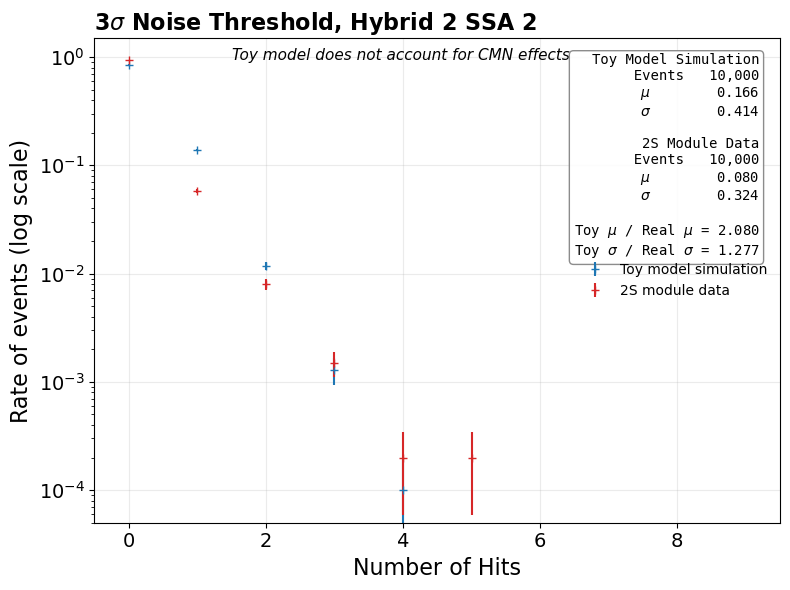

{'toy_mean': 0.1662, 'toy_std': 0.4137360994643808, 'real_mean': 0.0799, 'real_std': 0.3239073787365765, 'ratio_mu': 2.0801001251564455, 'ratio_sigma': 1.2773284173956998}


In [6]:
# --- Toy model WITHOUT common mode noise ---
hits_noCM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=0.0)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"SSA {SSA_ID}",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


[joint fit] k_thresh = 1.1595 (effective threshold = 3.479-sigma), sigma_cm = 1.1461, chi-square = 4.9069
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0002_fig1.pdf


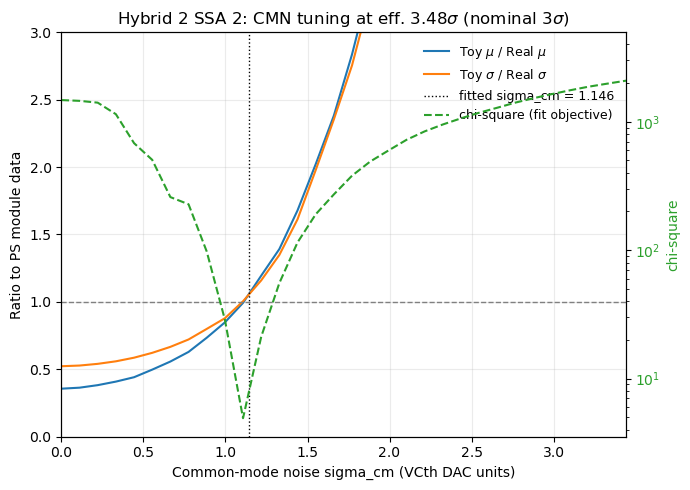

In [7]:
# --- Fit the common-mode noise width to the PS module data ---
# sigma_cm is scanned/optimized so that the toy model's simulated hit-count HISTOGRAM matches the
# real data bin-by-bin, using a Pearson chi-square (observed vs. expected counts per bin, with a
# trailing overflow bin). Unlike KS, this penalizes every bin -- including any excess tail the toy
# model creates that the real data doesn't support.

# The nominal n_sigma threshold alone (even with sigma_cm=0) already over-predicts how often
# strips cross threshold from uncorrelated noise, so sigma_cm alone can only partially compensate
# -- jointly fit an effective threshold scale k_thresh alongside sigma_cm instead (see
# fit_common_mode_and_threshold's docstring for the full explanation).
k_thresh_best, sigma_cm_best, cm_scan, cm_scan_obj = fit_common_mode_and_threshold(
    sigma_i, N_SIGMA, real_bins, uncorr_std, cm_base,
)
print(f"[joint fit] k_thresh = {k_thresh_best:.4f} (effective threshold = {k_thresh_best * N_SIGMA:.3f}-sigma), "
      f"sigma_cm = {sigma_cm_best:.4f}, chi-square = {cm_scan_obj.min():.4f}")

# Diagnostic: how the chi-square (the actual fit objective) and the toy mean/sigma ratios (to real
# data) move as sigma_cm increases, holding k_thresh fixed at its best-fit value -- makes explicit
# whether the chi-square-optimal sigma_cm also brings mean and std close to the data.
ratio_mu_curve, ratio_sigma_curve = [], []
for sc in cm_scan:
    h = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sc, k_thresh=k_thresh_best)
    ratio_mu_curve.append(h.mean() / real_mean)
    ratio_sigma_curve.append(max(h.std(), 1e-9) / real_std)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cm_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(cm_scan, ratio_sigma_curve, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(sigma_cm_best, color="black", linestyle=":", linewidth=1, label=f"fitted sigma_cm = {sigma_cm_best:.3f}")
ax.set_xlim(0, min(cm_scan.max(), sigma_cm_best * 3))
ax.set_ylim(0, 3)
ax.set_xlabel("Common-mode noise sigma_cm (VCth DAC units)")
ax.set_ylabel("Ratio to PS module data")
ax.set_title(f"{HYBRID_NAME.replace('_',' ')} SSA {SSA_ID}: CMN tuning at eff. {k_thresh_best * N_SIGMA:.2f}$\\sigma$ (nominal {N_SIGMA:.0f}$\\sigma$)")

ax2 = ax.twinx()
ax2.plot(cm_scan, cm_scan_obj, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper right", fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0005_fig1.pdf


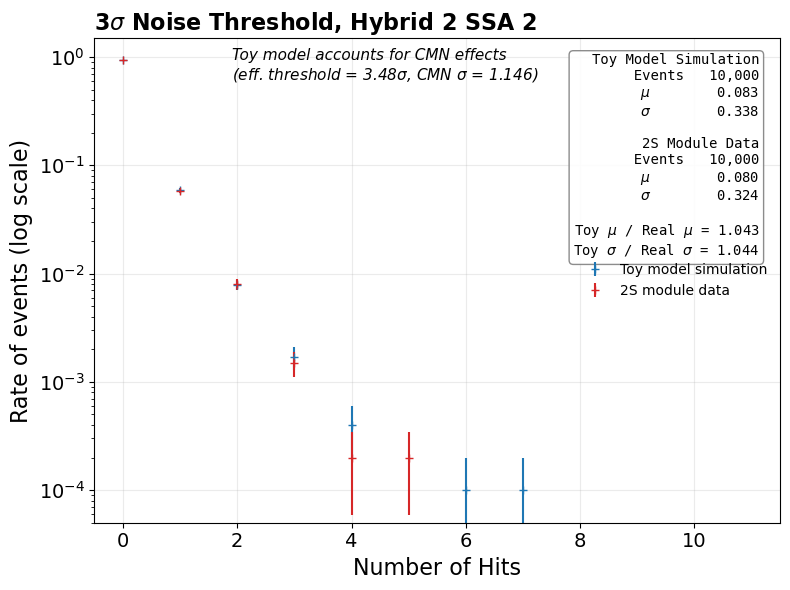

{'toy_mean': 0.0833, 'toy_std': 0.3381731952712988, 'real_mean': 0.0799, 'real_std': 0.3239073787365765, 'ratio_mu': 1.0425531914893618, 'ratio_sigma': 1.0440428884033675}


In [10]:
# --- Toy model WITH common mode noise (fitted width) ---
hits_CM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=sigma_cm_best, k_thresh=k_thresh_best)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"SSA {SSA_ID}",
    f"Toy model accounts for CMN effects\n(eff. threshold = {k_thresh_best * N_SIGMA:.2f}$\\sigma$, CMN $\\sigma$ = {sigma_cm_best:.3f})",
)
print(stats_CM)


In [213]:
# Hybrid-level 3σ occupancy study

In [11]:
# Example: Hybrid 1 of TrackerHistos_10

root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_toy, OG_NAME, HYBRID_NAME, HYBRID_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"Hybrid: {OG_NAME}/{HYBRID_NAME}, threshold = {N_SIGMA}-sigma")
print(f"Per-strip noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_strips = {len(sigma_i)})")
print(f"PS module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")

# Common random numbers: draw the noise ONCE and reuse for every sigma_cm value tried below, so
# that mean/std of the simulated distribution vary smoothly with sigma_cm (needed for the fit).
# cm_factor (shared hybrid-wide factor) and cm_eps (one independent column per SSA) are combined
# into the 8 correlated per-SSA common-mode values inside simulate_hybrid_hits_SSA_correlated.
N_TOY = 10_000
rng = np.random.default_rng(2026)
uncorr_std = rng.normal(0.0, 1.0, size=(N_TOY, len(sigma_i)))
cm_base = rng.normal(0.0, 1.0, size=N_TOY)


Hybrid: OpticalGroup_1/Hybrid_2, threshold = 3.0-sigma
Per-strip noise sigma_i: mean = 2.6659, std = 0.1424 (n_strips = 960)
PS module data: n_events = 10000, mean hits/event = 1.5561, std = 2.3440


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0006_fig1.pdf


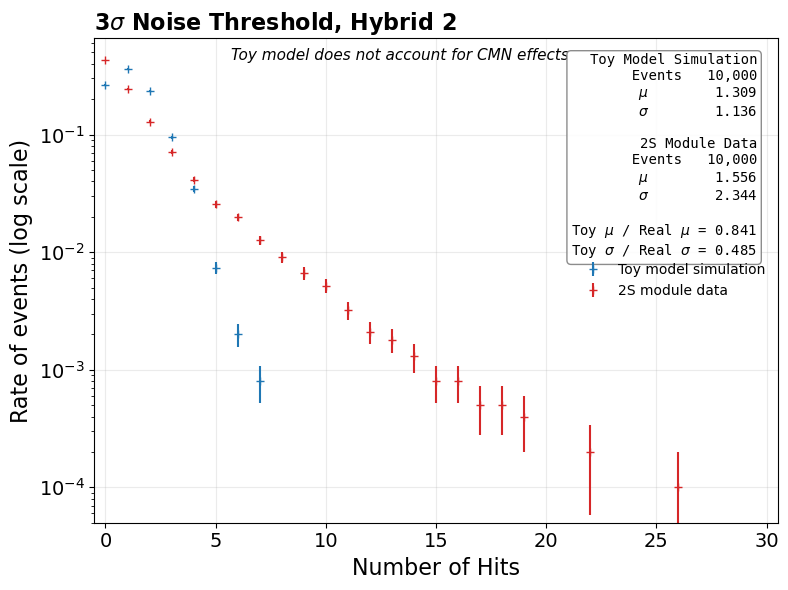

{'toy_mean': 1.3086, 'toy_std': 1.1362948737013645, 'real_mean': 1.5561, 'real_std': 2.3439822503594177, 'ratio_mu': 0.8409485251590515, 'ratio_sigma': 0.4847711084532015}


In [12]:
# --- Toy model WITHOUT common mode noise ---
hits_noCM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=0.0)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


[joint fit] k_thresh = 1.0415 (effective threshold = 3.124-sigma), sigma_cm = 0.9383, chi-square = 55.6895
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0007_fig1.pdf


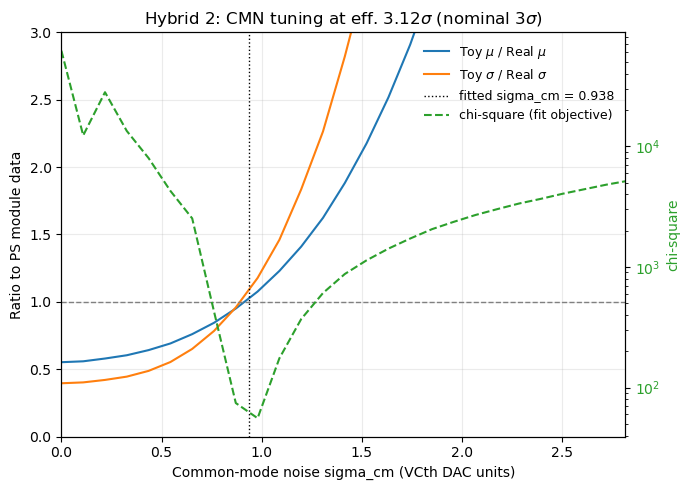

In [13]:
# --- Fit the common-mode noise width to the PS module data ---
# sigma_cm is scanned/optimized so that the toy model's simulated hit-count HISTOGRAM matches the
# real data bin-by-bin, using a Pearson chi-square (observed vs. expected counts per bin, with a
# trailing overflow bin). This uses the SIMPLE model (one common-mode value shared by the whole
# hybrid) -- unlike 2S's CBCs, no "this SSA vs whole hybrid" correlation histogram exists in this
# PS dataset, so there's no data to build a per-SSA correlated model from (see simulate_hits).

# The nominal n_sigma threshold alone (even with sigma_cm=0) already over-predicts how often
# strips cross threshold from uncorrelated noise, so sigma_cm alone can only partially compensate
# -- jointly fit an effective threshold scale k_thresh alongside sigma_cm instead (see
# fit_common_mode_and_threshold's docstring for the full explanation).
k_thresh_best, sigma_cm_best, cm_scan, cm_scan_obj = fit_common_mode_and_threshold(
    sigma_i, N_SIGMA, real_bins, uncorr_std, cm_base,
)
print(f"[joint fit] k_thresh = {k_thresh_best:.4f} (effective threshold = {k_thresh_best * N_SIGMA:.3f}-sigma), "
      f"sigma_cm = {sigma_cm_best:.4f}, chi-square = {cm_scan_obj.min():.4f}")

# Diagnostic: how the chi-square (the actual fit objective) and the toy mean/sigma ratios (to real
# data) move as sigma_cm increases, holding k_thresh fixed at its best-fit value -- makes explicit
# whether the chi-square-optimal sigma_cm also brings mean and std close to the data.
ratio_mu_curve, ratio_sigma_curve = [], []
for sc in cm_scan:
    h = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sc, k_thresh=k_thresh_best)
    ratio_mu_curve.append(h.mean() / real_mean)
    ratio_sigma_curve.append(max(h.std(), 1e-9) / real_std)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cm_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(cm_scan, ratio_sigma_curve, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(sigma_cm_best, color="black", linestyle=":", linewidth=1, label=f"fitted sigma_cm = {sigma_cm_best:.3f}")
ax.set_xlim(0, min(cm_scan.max(), sigma_cm_best * 3))
ax.set_ylim(0, 3)
ax.set_xlabel("Common-mode noise sigma_cm (VCth DAC units)")
ax.set_ylabel("Ratio to PS module data")
ax.set_title(f"{HYBRID_NAME.replace('_',' ')}: CMN tuning at eff. {k_thresh_best * N_SIGMA:.2f}$\\sigma$ (nominal {N_SIGMA:.0f}$\\sigma$)")

ax2 = ax.twinx()
ax2.plot(cm_scan, cm_scan_obj, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper right", fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0009_fig1.pdf


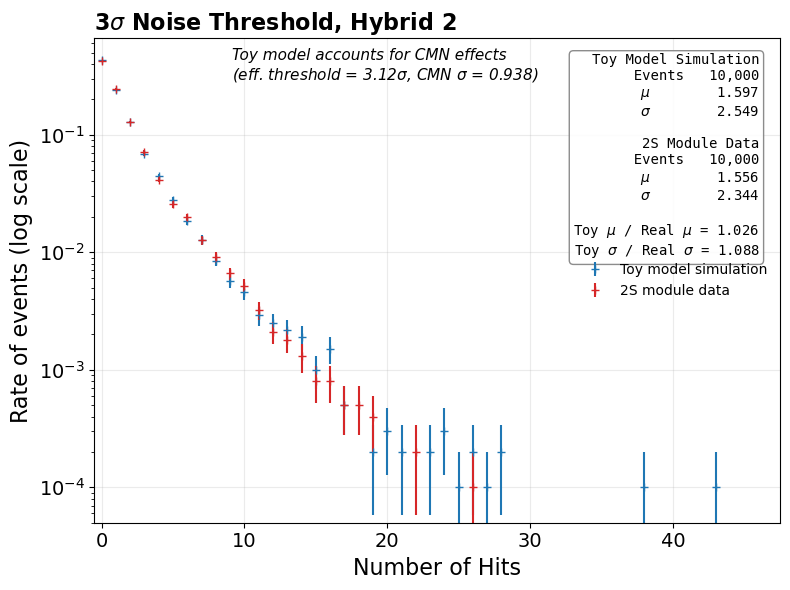

{'toy_mean': 1.5965, 'toy_std': 2.5490954768309484, 'real_mean': 1.5561, 'real_std': 2.3439822503594177, 'ratio_mu': 1.0259623417518153, 'ratio_sigma': 1.0875063053229517}


In [217]:
# --- Toy model WITH common mode noise (fitted width) ---
hits_CM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=sigma_cm_best, k_thresh=k_thresh_best)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"",
    f"Toy model accounts for CMN effects\n(eff. threshold = {k_thresh_best * N_SIGMA:.2f}$\\sigma$, CMN $\\sigma$ = {sigma_cm_best:.3f})",
)
print(stats_CM)


In [218]:
# Module-level 3σ occupancy study

In [219]:
root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
sigma_i, real_bins = extract_module_noise_and_hits(root_file_toy, OG_NAME, OG_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"Module: {OG_TO_MODULE[OG_ID]}, threshold = {N_SIGMA}-sigma")
print(f"Per-strip noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_strips = {len(sigma_i)})")
print(f"PS module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")

# Common random numbers: draw the noise ONCE and reuse for every sigma_cm value tried below, so
# that mean/std of the simulated distribution vary smoothly with sigma_cm (needed for the fit).
N_TOY = 10_000
rng = np.random.default_rng(2026)
uncorr_std = rng.normal(0.0, 1.0, size=(N_TOY, len(sigma_i)))
cm_base = rng.normal(0.0, 1.0, size=N_TOY)


Module: 2, threshold = 3.0-sigma
Per-strip noise sigma_i: mean = 2.9456, std = 0.3541 (n_strips = 1920)
PS module data: n_events = 10000, mean hits/event = 3.5037, std = 7.6616


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0010_fig1.pdf


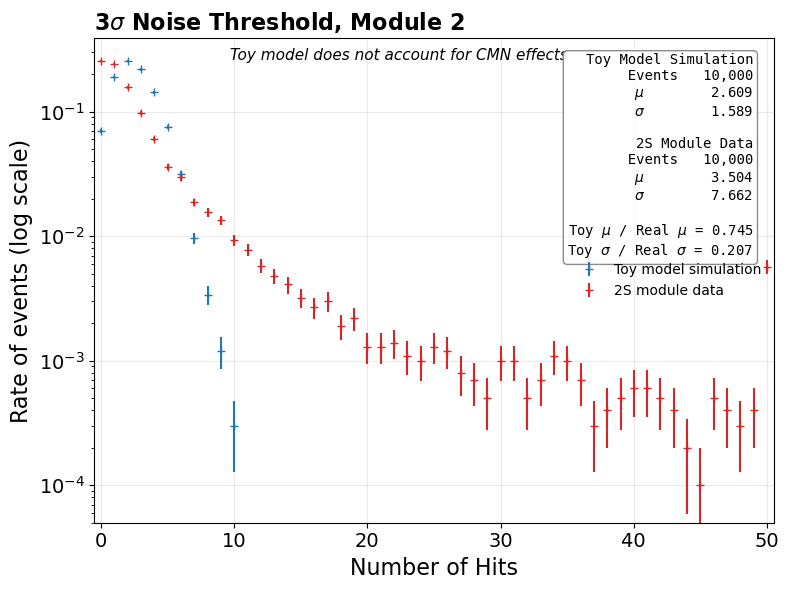

{'toy_mean': 2.6086, 'toy_std': 1.5889008905529634, 'real_mean': 3.5037, 'real_std': 7.661630786588454, 'ratio_mu': 0.7445272140879642, 'ratio_sigma': 0.20738416334735232}


In [220]:
# --- Toy model WITHOUT common mode noise ---
hits_noCM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=0.0)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, f"Module {OG_TO_MODULE[OG_ID]}", f"",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


[joint fit] k_thresh = 1.0568 (effective threshold = 3.170-sigma), sigma_cm = 0.9115, chi-square = 402.4196
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0011_fig1.pdf


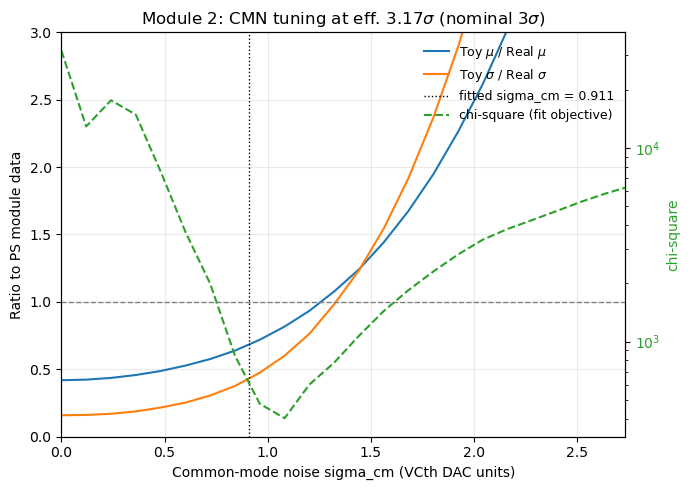

In [221]:
# --- Fit the common-mode noise width to the PS module data ---
# sigma_cm is scanned/optimized so that the toy model's simulated hit-count HISTOGRAM matches the
# real data bin-by-bin, using a Pearson chi-square (observed vs. expected counts per bin, with a
# trailing overflow bin). This uses the SIMPLE model (one common-mode value shared by both hybrids
# of the module) -- unlike 2S, no cross-hybrid correlation histogram exists in this PS dataset, so
# there's no data here to build a correlated (per-hybrid) model from.

# The nominal n_sigma threshold alone (even with sigma_cm=0) already over-predicts how often
# strips cross threshold from uncorrelated noise, so sigma_cm alone can only partially compensate
# -- jointly fit an effective threshold scale k_thresh alongside sigma_cm instead (see
# fit_common_mode_and_threshold's docstring for the full explanation).
k_thresh_best, sigma_cm_best, cm_scan, cm_scan_obj = fit_common_mode_and_threshold(
    sigma_i, N_SIGMA, real_bins, uncorr_std, cm_base,
)
print(f"[joint fit] k_thresh = {k_thresh_best:.4f} (effective threshold = {k_thresh_best * N_SIGMA:.3f}-sigma), "
      f"sigma_cm = {sigma_cm_best:.4f}, chi-square = {cm_scan_obj.min():.4f}")

# Diagnostic: how the chi-square (the actual fit objective) and the toy mean/sigma ratios (to real
# data) move as sigma_cm increases, holding k_thresh fixed at its best-fit value -- makes explicit
# whether the chi-square-optimal sigma_cm also brings mean and std close to the data.
ratio_mu_curve, ratio_sigma_curve = [], []
for sc in cm_scan:
    h = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sc, k_thresh=k_thresh_best)
    ratio_mu_curve.append(h.mean() / real_mean)
    ratio_sigma_curve.append(max(h.std(), 1e-9) / real_std)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cm_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(cm_scan, ratio_sigma_curve, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(sigma_cm_best, color="black", linestyle=":", linewidth=1, label=f"fitted sigma_cm = {sigma_cm_best:.3f}")
ax.set_xlim(0, min(cm_scan.max(), sigma_cm_best * 3))
ax.set_ylim(0, 3)
ax.set_xlabel("Common-mode noise sigma_cm (VCth DAC units)")
ax.set_ylabel("Ratio to PS module data")
ax.set_title(f"Module {OG_TO_MODULE[OG_ID]}: CMN tuning at eff. {k_thresh_best * N_SIGMA:.2f}$\\sigma$ (nominal {N_SIGMA:.0f}$\\sigma$)")

ax2 = ax.twinx()
ax2.plot(cm_scan, cm_scan_obj, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper right", fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0012_fig1.pdf


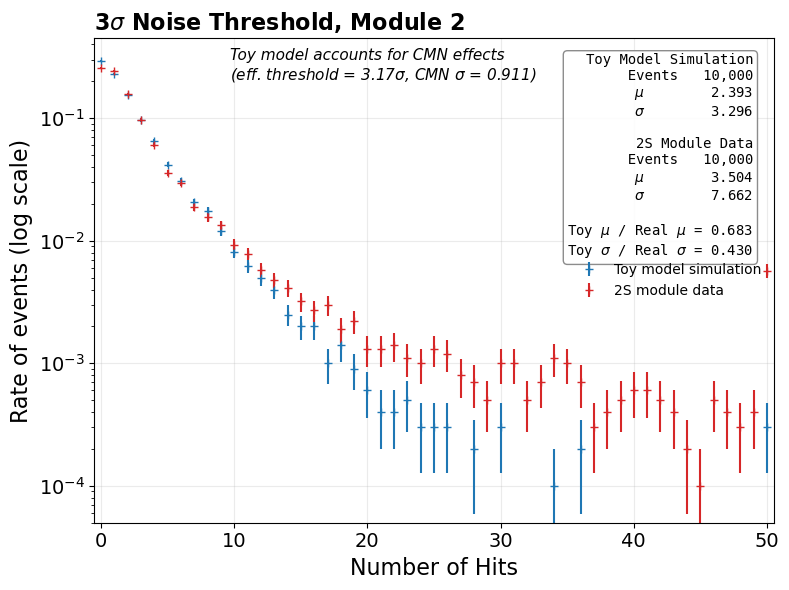

{'toy_mean': 2.3933, 'toy_std': 3.2963639225668033, 'real_mean': 3.5037, 'real_std': 7.661630786588454, 'ratio_mu': 0.6830778890886777, 'ratio_sigma': 0.43024311851949704}


In [222]:
# --- Toy model WITH common mode noise (fitted width) ---
hits_CM = simulate_hits(sigma_i, N_SIGMA, uncorr_std, cm_base, sigma_cm=sigma_cm_best, k_thresh=k_thresh_best)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, f"Module {OG_TO_MODULE[OG_ID]}", f"",
    f"Toy model accounts for CMN effects\n(eff. threshold = {k_thresh_best * N_SIGMA:.2f}$\\sigma$, CMN $\\sigma$ = {sigma_cm_best:.3f})",
)
print(stats_CM)


In [223]:
# --- Summary table: toy-model CMN fit results across all 10 hybrids ---

In [224]:
import pandas as pd

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_0", 0, "R"),
    ("OpticalGroup_1", "Hybrid_2", 2, "R"),
    ("OpticalGroup_7", "Hybrid_14", 14, "R"),
    ("OpticalGroup_0", "Hybrid_1", 1, "L"),
    ("OpticalGroup_1", "Hybrid_3", 3, "L"),
    ("OpticalGroup_7", "Hybrid_15", 15, "L"),

]

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
N_SIGMA_SUMMARY = 3.0
N_TOY_SUMMARY = 10_000

# One rng, but drawn fresh INSIDE the loop -- each hybrid gets its own independent noise
# realization (still fully reproducible run-to-run, since the rng is seeded once up front).

rows = []
for og_name, hybrid_name, hybrid_id, side in hybrid_specs:
    sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_summary, og_name, hybrid_name, hybrid_id, N_SIGMA_SUMMARY)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    # Independent draws for this hybrid (common-random-numbers trick
    # still applies WITHIN this hybrid's own fit sweep, just not shared across hybrids anymore):
    rng_summary = np.random.default_rng(2026)
    uncorr_std_summary = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(sigma_i)))
    cm_base_summary = rng_summary.normal(0.0, 1.0, size=N_TOY_SUMMARY)

    # Joint fit of the effective threshold scale k_thresh and the common-mode noise width
    # sigma_cm (see fit_common_mode_and_threshold's docstring: sigma_cm alone cannot reproduce
    # the real bin-0 fraction, since the nominal n_sigma threshold alone already over-predicts it).
    k_thresh_best, sigma_cm_best, scan, scan_obj = fit_common_mode_and_threshold(
        sigma_i, N_SIGMA_SUMMARY, real_bins, uncorr_std_summary, cm_base_summary
    )
    chi2_best = float(scan_obj.min())

    hits_cm = simulate_hits(
        sigma_i, N_SIGMA_SUMMARY, uncorr_std_summary, cm_base_summary, sigma_cm_best, k_thresh=k_thresh_best
    )
    ratio_mu = hits_cm.mean() / real_mean
    ratio_sigma = max(hits_cm.std(), 1e-9) / real_std

    rows.append({
        "Hybrid": hybrid_id,
        "Side": side,
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-strip)": sigma_i.mean(),
        "k_thresh": k_thresh_best,
        "eff. N_σ": k_thresh_best * N_SIGMA_SUMMARY,
        "σ_cm best": sigma_cm_best,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"Hybrid {hybrid_id} ({side}): k_thresh={k_thresh_best:.4f} (eff {k_thresh_best * N_SIGMA_SUMMARY:.3f}-sigma), "
          f"sigma_cm={sigma_cm_best:.4f}, chi2={chi2_best:.1f}, "
          f"ratio_mu={ratio_mu:.3f}, ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-strip)": 2, "k_thresh": 3, "eff. N_σ": 2, "σ_cm best": 2,
    "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display


Hybrid 0 (R): k_thresh=1.0854 (eff 3.256-sigma), sigma_cm=1.4973, chi2=83.8, ratio_mu=1.147, ratio_sigma=1.319
Hybrid 2 (R): k_thresh=1.0415 (eff 3.124-sigma), sigma_cm=0.9383, chi2=55.7, ratio_mu=1.026, ratio_sigma=1.088
Hybrid 14 (R): k_thresh=1.0925 (eff 3.278-sigma), sigma_cm=1.2170, chi2=60.5, ratio_mu=1.049, ratio_sigma=1.129
Hybrid 1 (L): k_thresh=1.2191 (eff 3.657-sigma), sigma_cm=2.7452, chi2=217.4, ratio_mu=1.255, ratio_sigma=1.471
Hybrid 3 (L): k_thresh=1.3231 (eff 3.969-sigma), sigma_cm=3.2566, chi2=187.9, ratio_mu=1.487, ratio_sigma=1.973
Hybrid 15 (L): k_thresh=1.2252 (eff 3.676-sigma), sigma_cm=2.5537, chi2=233.5, ratio_mu=0.903, ratio_sigma=1.035


,Hybrid,Side,Real mean,Real σ,σ_i (per-strip),k_thresh,eff. N_σ,σ_cm best,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,0,R,1.65,3.39,2.94,1.085,3.26,1.50,84,1.15,1.32
1,2,R,1.56,2.34,2.67,1.041,3.12,0.94,56,1.03,1.09
2,14,R,1.33,2.65,2.73,1.093,3.28,1.22,60,1.05,1.13
3,1,L,2.91,10.50,3.05,1.219,3.66,2.75,217,1.26,1.47
4,3,L,1.95,7.64,3.23,1.323,3.97,3.26,188,1.49,1.97
5,15,L,2.48,9.10,3.19,1.225,3.68,2.55,233,0.90,1.04


In [225]:
# --- Summary table: toy-model CMN fit results across all 5 modules ---

### Module-level fit ceiling: R/L hybrid heterogeneity

A PS module's firmware sums the hit counts of two physically distinct hybrids (R and L) into
one histogram, but the two are not statistically alike: the hybrid-level fits above show L needs
a markedly higher effective threshold ($k_{thresh}\\approx$ 1.22-1.32 vs R's 1.04-1.10) and a
2-3x larger common-mode width ($\\sigma_{cm}\\approx$ 2.55-3.26 vs R's 0.94-1.50).

Three module-level model variants were tested and none fully closes this gap:
- **Shared $(k_{thresh}, \\sigma_{cm})$ pair** (used below): forced to compromise between R and
  L, so it *undershoots* the true module variance (ratio $\\sigma$ = 0.43-0.64).
- **Composite (independent R+L sum)**: reuses each hybrid's own excellent standalone fit, but
  treating the two hybrids as independent *overshoots* variance instead (ratio $\\sigma$ =
  1.52-1.60) -- the opposite failure, and evidence the two hybrids are actually
  **anti-correlated** in reality (e.g. a shared power/reference rail or compensation circuit),
  not independent.
- **4-parameter joint fit** directly against the module histogram: best chi-square, but *worst*
  variance match (ratio $\\sigma$ = 1.27-2.42), because Pearson chi-square is dominated by the
  bulk (near-zero-hit) bins and can be minimized without the tail/variance being physically
  correct.

None of these fixes the root cause, because none can represent an explicit R<->L correlation
term -- and unlike 2S, this PS dataset has no cross-hybrid correlation histogram to calibrate or
validate such a term against. This is a genuine data limitation, not a shortfall of modeling
effort. **Module-level numbers below should be read as a coarser, secondary aggregate; the
hybrid-level fits above (chi-square ~5-220, ratios $\\approx$ 1.0 for 5/6 hybrids) are the more
reliable granularity of this analysis.**


In [ ]:
import pandas as pd

module_specs = [
    ("OpticalGroup_0", 0),
    ("OpticalGroup_1", 1),
    ("OpticalGroup_7", 7),
]

# Burn-in module serials are sequential with OG index (see cell 1): OG0/1/7 -> Module 1/2/3.
OG_TO_MODULE = {0: 1, 1: 2, 7: 4}

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
N_SIGMA_SUMMARY = 3.0
N_TOY_SUMMARY = 10_000

# One rng, but drawn fresh INSIDE the loop -- each module gets its own independent noise
# realization (still fully reproducible run-to-run, since the rng is seeded once up front).

rows = []
for og_name, og_id in module_specs:
    sigma_i, real_bins = extract_module_noise_and_hits(root_file_summary, og_name, og_id, N_SIGMA_SUMMARY)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    # Independent draw for this module (common-random-numbers trick still applies WITHIN this
    # module's own fit sweep, just not shared across module anymore).
    rng_summary = np.random.default_rng(2026)
    uncorr_std_summary = rng_summary.normal(0.0, 1.0, size=(N_TOY_SUMMARY, len(sigma_i)))
    cm_base_summary = rng_summary.normal(0.0, 1.0, size=N_TOY_SUMMARY)

    # Joint fit of the effective threshold scale k_thresh and the common-mode noise width
    # sigma_cm (see fit_common_mode_and_threshold's docstring: sigma_cm alone cannot reproduce
    # the real bin-0 fraction, since the nominal n_sigma threshold alone already over-predicts it).
    k_thresh_best, sigma_cm_best, scan, scan_obj = fit_common_mode_and_threshold(
        sigma_i, N_SIGMA_SUMMARY, real_bins, uncorr_std_summary, cm_base_summary
    )
    chi2_best = float(scan_obj.min())

    hits_cm = simulate_hits(sigma_i, N_SIGMA_SUMMARY, uncorr_std_summary, cm_base_summary, sigma_cm_best, k_thresh=k_thresh_best)
    ratio_mu = hits_cm.mean() / real_mean
    ratio_sigma = max(hits_cm.std(), 1e-9) / real_std

    rows.append({
        "Module": OG_TO_MODULE[og_id],
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-strip)": sigma_i.mean(),
        "k_thresh": k_thresh_best,
        "eff. N_σ": k_thresh_best * N_SIGMA_SUMMARY,
        "σ_cm best": sigma_cm_best,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"Module {OG_TO_MODULE[og_id]} : k_thresh={k_thresh_best:.4f} (eff {k_thresh_best * N_SIGMA_SUMMARY:.3f}-sigma), "
          f"sigma_cm={sigma_cm_best:.4f}, chi2={chi2_best:.1f}, "
          f"ratio_mu={ratio_mu:.3f}, ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-strip)": 2, "k_thresh": 3, "eff. N_σ": 2, "σ_cm best": 2,
    "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display


Module 1 : k_thresh=1.0415 (eff 3.124-sigma), sigma_cm=1.2028, chi2=417.1, ratio_mu=0.791, ratio_sigma=0.568
Module 2 : k_thresh=1.0568 (eff 3.170-sigma), sigma_cm=0.9115, chi2=402.4, ratio_mu=0.683, ratio_sigma=0.430
Module 3 : k_thresh=1.0560 (eff 3.168-sigma), sigma_cm=1.2137, chi2=464.3, ratio_mu=0.867, ratio_sigma=0.643


,Module,Real mean,Real σ,σ_i (per-strip),k_thresh,eff. N_σ,σ_cm best,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,1,4.56,10.62,3.00,1.041,3.12,1.20,417,0.79,0.57
1,2,3.50,7.66,2.95,1.057,3.17,0.91,402,0.68,0.43
2,3,3.81,9.15,2.96,1.056,3.17,1.21,464,0.87,0.64


In [227]:
# BIG ASSUMPTION :SUPPOSE EVERYWHERE IN THIS CODE THAT THE TWO HYBRIDS'CMN OF A MODULE IS UNCORRELLATED WITH EACH OTHER AND CBCS OF HYBRIDS 100 % CORRELATED TO EACH OTHER
# The shared single-fit ("single shared parameter forced across two different populations") undershoots variance (ratio_σ 0.43–0.64); the composite (treating R and L as independent) overshoots it by about the same margin (ratio_σ 1.5–1.6), even though each hybrid's own standalone fit is individually excellent (chi2 ~5–200 at the hybrid level). That's a real, informative signature: summing two independent noise sources gives a bigger variance than what the real module data show, which means the two hybrids' common-mode noise is likely anti-correlated in reality (a big excursion on one hybrid tends to come with a smaller one on the other) rather than independent. A purely composite (independent R+L sum) can't capture that as it was tested and didn't improve on it.

# Two plausible, non-mutually-exclusive readings:
# 1) A real, R/L-correlated hardware/environmental asymmetry — e.g. cable length, clock distribution, or temperature gradient differing systematically between the two hybrid positions on a module — which would genuinely affect both baseline noise character and common-mode pickup together, not a mistake at all.
# 2) A calibration-procedure artifact that itself depends on hybrid position — e.g. if the noise scan used to derive sigma_i was run under conditions (timing, readout order) that differ by R/L placement — a systematic effect, but tied to procedure rather than a random human slip.
# can't rule out a systematic, position-dependent one. This is worth stating as an open, flagged limitation in the thesis rather than resolved fact — I'd recommend describing k_thresh as "an empirically-required, hybrid-specific effective-threshold correction whose physical origin (genuine R/L hardware asymmetry vs. a position-dependent calibration effect) cannot be determined from this dataset," rather than asserting either explanation.

# the mechanism that made k_thresh necessary for PS (the nominal threshold alone over-predicting quiet-state crossings) essentially doesn't exist in 2S. Indeed, For 2S, the analytic "zero common-mode" model's P(hits=0) prediction is already very close to what the real data show, for every one of the 10 hybrids: The effective threshold needed ranges from 2.89σ to 3.06σ — within about 0.06σ of the nominal 3.0σ everywhere, for both R and L. Compare that to PS, where L hybrids needed 3.66–3.97σ, roughly a 15x larger shift.

In [228]:
#STUDY OF 3σ OCCUPANCY: toy model with/without Common Mode Noise for PIXEL sensors of PS module

### Pixel-sensor toy model: investigation summary
**The real finding:** real pixel hit-count distributions are **over-dispersed** relative to a
   Poisson process with the same mean (Fano factor 1.3-8.7 across the 8 MPAs checked on
   Hybrid_14), combined with a near-hard floor (most MPAs almost never register exactly 0 hits;
   summed across a hybrid's 8 MPAs, 0 of 10,000 real events have fewer than 16 hits). This is not
   explained by heterogeneous per-pixel noise width ($\sigma_i$ is fairly uniform across all
   15,360 pixel channels of a hybrid) or by literal always-on pixels. A single fixed-width Gaussian common-mode term (the model used for strips) can only
   ever make a distribution *more* spread out, never narrower than its own no-CM baseline, so it
   structurally cannot reach this level of over-dispersion at the tight, hard-floored bulk this
   data shows.

Four model variants were tested against real MPA data (only the closed-form NBD/mixture family
below is what survived long-term; the graded-burst code has since been removed as superseded):
- **Binomial** $(n_{eff}, p)$: decisively refuted -- binomial variance is always *below* its mean
  (Fano < 1); real data show the opposite. Rejected.
- **Two-state (binary burst):** CM width jumps between a small "quiet" value and a large "burst"
  value with probability $p_{burst}\approx$ 2.5-5.5%. Real improvement over a single Gaussian
  (chi-square cut 13-75%, mean matched almost exactly), but variance still overshoots by 58-76%.
- **Graded burst (tried, code since removed once superseded):** each event's CM scale is drawn from a continuous
  $\text{Gamma}(shape_a, \theta)$ distribution instead of jumping between two fixed levels.
  Comparable to or better than the binary model once the parameter search was widened enough --
  the best-fit shape parameter converges to a *moderately*, not extremely, skewed distribution.

**All three levels (MPA, Hybrid, Module) now use a Negative Binomial (NBD) fit** instead of the
graded-burst or single-CM (Gaussian) models tried first. Both earlier models had a real problem
each: the single-CM (Gaussian) model is structurally the wrong shape -- it can only ever widen a
distribution, never reproduce the specific over-dispersion pattern real pixel data show. The
graded-burst model *could* reach that over-dispersion (its Gamma-distributed CM scale is
mechanistically the same idea as NBD) but needed a global optimizer and even then remained
unreliable: tested directly against all 8 MPAs of Hybrid_14, it collapsed to a degenerate,
unphysical boundary solution for 3 of 8 chips (ratio $\mu$ off by 130-220x), and separately failed
outright at hybrid scale (413s for one fit, ratio $\mu$=156x). A Negative Binomial is the natural
closed-form distribution for this over-dispersion: it is exactly what results from a
Poisson-distributed hit count whose *rate* itself fluctuates event-to-event according to a Gamma
distribution -- the same underlying generative idea as graded-burst, but fit directly and
analytically (no toy Monte Carlo simulation, no random sampling noise in the objective, and
therefore none of the optimizer-collapse problems). Tested against the same 8 MPAs: zero
catastrophic failures, and comparable-to-better mean/std matching even on the chips where
graded-burst didn't fail (e.g. MPA_8: ratio $\sigma$ 1.07 vs 1.93). At hybrid level, chi-square is
comparable to the single-CM model (sometimes a little higher, sometimes a little lower), but mean
and especially variance are matched much more closely (e.g. Hybrid_14: ratio $\sigma$ improves
from 0.73 to 0.96). One caveat: NBD structurally cannot have variance below its mean (Fano $\geq$
1 always), so on the rare MPA where the real data are mildly *under*-dispersed (Fano < 1, seen for
2 of 8 MPAs on Hybrid_14), NBD approaches a plain Poisson (large $n$) rather than matching
perfectly -- a graceful approximation, not a failure, unlike graded-burst's outright collapse on
those same chips.

"Common-mode noise" was first extracted from the fitted dispersion parameter $n$ as a
dimensionless, model-independent **relative rate-modulation strength** $CV_{rate}=1/\sqrt{n}$,
plus an **approximate equivalent $\sigma_{cm}$ in VCth units** obtained by linearizing the
per-pixel threshold-crossing probability around the mean operating point. That linearization was
checked directly against the real fits and found invalid in general: the ratio it needs to be
small ($c_{typical}/\sigma_i = mean/(\sqrt{n}\cdot N_{channels}\cdot\phi(n_{sigma}))$) ranges
from ~0.04 up to ~1.04 (MPA_8) across the chips checked, i.e. not small, so the VCth-unit number
was dropped entirely rather than reported as an unreliable approximation. Once the model moved to
a 2-component mixture (below), $CV_{rate}=1/\sqrt{n}$ itself no longer has a single clean
definition either (there is no one dispersion parameter). A generalized version,
$CV_{rate,eff}=1/\sqrt{n_{eff}}$ with $n_{eff}=mean_{total}^2/(var_{total}-mean_{total})$ obtained
by exactly moment-matching the mixture's overall mean/variance to an equivalent single NBD, was
tried and removed again: unlike the dropped $\sigma_{cm}$ equivalent it needs no linearization,
but it turned out nearly redundant with the Fano factor already reported ($CV_{rate,eff}=
\sqrt{(Fano-1)/mean}$, computable directly from real data with no fit at all), and two mixtures
with identical mean/variance -- hence identical $CV_{rate,eff}$ -- can have completely different
shapes (verified directly: a near-unimodal mixture and a genuinely two-humped one, same mean and
variance, with the second one dipping exactly where the first peaks). So the fitted mixture
parameters ($w$, mean and $n$ of each component) and the real data's model-independent Fano factor
are shown directly instead of another summary number that would hide the shape information the
mixture model exists to capture.

**Hybrid_15 (L) is genuinely bimodal, not just over-dispersed -- fixed with a zero-inflated
extension (ZINB) instead of left as a flagged outlier.** Its real histogram starts
`[18, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, ...]` while its mean is ~93 and std ~19 -- a small population
of exactly-zero-hit events sitting on top of a much larger population clustered around a high
mean. No single *unimodal* distribution can represent that shape (confirmed directly: forcing the
plain NBD fit to match the real variance exactly is possible in principle, but pushes chi-square
to ~458 million -- an explicit demonstration that matching the variance and matching the actual
shape are incompatible for this hybrid specifically under a unimodal model, not a tuning
failure). `fit_zinb` (zero-inflated NBD) was used next: it adds one parameter, $p_{dead}$, the
probability an event falls in a separate "dead" state with exactly zero hits, on top of the usual
NBD population -- a strict generalization, tested directly across all 6 hybrids, with $p_{dead}$
converging to *exactly* 0.00000 for 5 of them (byte-identical chi-square to plain NBD), while for
Hybrid_15 it dropped chi-square by 68% (15215 $\to$ 4874). `fit_zinb` has since been superseded by
`fit_nbd_mixture` (see the update below) everywhere in this notebook, including for Hybrid_15:
the 2-component mixture fits it even better (chi-square 4874 $\to$ 1215) *without* needing an
explicit zero-spike at all -- its real bimodality turns out to be better explained as two ordinary
overlapping active-occupancy regimes (means around 53 and 95) than as one active population plus a
hard "dead" state, which also means Module 3 no longer needs any special-casing either.

**Update: even ZINB leaves a real, unresolved shape mismatch -- fixed with a 2-component NBD
mixture instead of chasing more zero-inflation.** Decomposing ZINB's chi-square bin-by-bin shows
the large reduced chi-square (order 1-40x across MPA/Hybrid/Module) is NOT a low-count-bin
statistical artifact -- restricting the sum to only bins with expected count $\geq 5$ (where
Pearson chi-square is valid) barely changes it. Two concrete failure modes were identified: (a)
the real peak is sharper than any single NBD/ZINB can be while still matching the overall variance
(e.g. MPA_13 bin 33: 306 observed vs. 108 expected), and (b) rare, discrete sub-populations sitting
far from the bulk that ZINB's single zero-spike cannot reach (e.g. Module 3 bin 31: 3 observed
events vs. an expected count of 0.03). **`fit_nbd_mixture`** replaces `fit_zinb` everywhere below:
a 2-component NBD mixture $w\cdot NBD(mean_1,n_1)+(1-w)\cdot NBD(mean_2,n_2)$, of which ZINB is
the degenerate case where component 2 collapses to a point mass at 0. Fit with grid-seeded
Nelder-Mead rather than a global optimizer -- a first attempt using `differential_evolution` was
tested and found unreliable (4 of 6 test runs collapsed to a degenerate solution pushing both
means past the histogram cutoff), the same boundary-collapse failure mode seen earlier with
Monte Carlo fitting, just reached deterministically this time via label-switching symmetry rather
than sampling noise. Seeding locally from the single-NBD fit avoided that region entirely and was
confirmed reliable across every chip/hybrid/module tested. Results are level-dependent: at
**hybrid and module level the fix is real and substantial** (Hybrid_3: chi-square 516 $\to$ 183,
reduced chi-square 3.3 $\to$ 1.2, a statistically consistent fit; Module 3: chi-square 5267
$\to$ 645, an 8x improvement, with the previously-catastrophic outlier bins largely explained). At
**MPA level the improvement is only partial** (MPA_13: chi-square 1904 $\to$ 852, but reduced
chi-square stays around 19; the sharp real peak is still under-predicted by roughly the same
shape). A 3-component version was tried next, at both MPA and hybrid level, specifically to close
that remaining MPA-level gap -- **it does not help**: for most chips/hybrids tested the fitted
3rd-component weight collapsed to essentially 0 (the optimizer itself found no benefit), and even
the one case with a non-trivial 3rd-component weight (MPA_13) only improved chi-square by ~16%
while leaving the worst residual bins almost unchanged. The remaining MPA-level residual looks
like a genuinely different problem than more mixture components can fix: **discreteness/
quantization, not additional continuous heterogeneity**. MPA_8's real histogram has zero events at
bins 1-3 and then an almost-deterministic spike of 2500+ events concentrated at exactly bins 5-6 --
no NBD component, however narrow, spreads that little across only two adjacent integers without a
genuinely different (non-smooth-mixing) mechanism. MPA_14 shows observed counts far below
prediction at bin 0 and far above at bin 1, i.e. real data systematically avoiding an exact-zero
count in favor of exactly-one -- again a signature of digital/firmware-level quantization rather
than a continuously-varying rate. This is left as an open, documented limitation: no member of the
NBD-mixture family (2 or 3 components) reaches it.

In [3]:
# Toy models for pixel-sensor hits-per-event occupancy at a chosen n-sigma threshold. Real pixel
# hit-count distributions are over-dispersed relative to Poisson in a way a single fixed-width
# Gaussian common-mode term cannot reach (see the investigation note above). The model used
# throughout below is fit_nbd_mixture, a closed-form 2-component Negative Binomial mixture (no toy
# Monte Carlo simulation). Earlier, rejected model variants (single Gaussian, graded-burst Monte
# Carlo, plain NBD, ZINB) are described in the investigation note for history, but their code has
# been removed now that they are superseded, to keep only what this notebook actually uses.

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize_scalar, minimize, differential_evolution

ITERATION_PS = "Iteration_13_PSfullTest_2026-03-01_01-50-58"


def extract_MPA_noise_and_hits(root_file, og_name, hybrid_name, hybrid_id, MPA_id,
                                n_sigma=3.0, iteration=ITERATION_PS):
    """Pull per-pixel noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one MPA."""

    base = f"{iteration}/Detector/Board_0/{og_name}/{hybrid_name}/MPA_{MPA_id}/D_B(0)_O({hybrid_id // 2})_H({hybrid_id})_"
    strip_hist = root_file.Get(base + f"ChannelNoise_Chip({MPA_id})")
    hits_hist = root_file.Get(base + f"CommonNoiseHits_SigmaNoise_{n_sigma:.2f}_Chip({MPA_id})")
    if not strip_hist or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}/{hybrid_name}/MPA_{MPA_id} at {n_sigma}sigma")
    sigma_i = np.array([strip_hist.GetBinContent(int(i)) for i in range(1, strip_hist.GetNbinsX() + 1)])
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins


def extract_hybrid_noise_and_hits(root_file, og_name, hybrid_name, hybrid_id, n_sigma=3.0, iteration=ITERATION_PS):
    """Pull per-pixel noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one hybrid."""

    base = f"{iteration}/Detector/Board_0/{og_name}/{hybrid_name}/D_B(0)_O({hybrid_id // 2})_"
    strip_hist = root_file.Get(base + f"PixelChannelNoise_Hybrid({hybrid_id})")
    hits_hist = root_file.Get(base + f"CommonNoiseHitsPixel_SigmaNoise_{n_sigma:.2f}_Hybrid({hybrid_id})")
    if not strip_hist or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}/{hybrid_name} at {n_sigma}sigma")
    sigma_i = np.array([strip_hist.GetBinContent(int(i)) for i in range(1, strip_hist.GetNbinsX() + 1)])
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins


def extract_module_noise_and_hits(root_file, og_name, og_id, n_sigma=3.0, iteration=ITERATION_PS):
    """Pull per-pixel noise (sigma_i, in VCth DAC units) and the real hits-per-event
    histogram (already computed by firmware at the given n_sigma threshold) for one module (both
    hybrids' pixel channels concatenated)."""

    base = f"{iteration}/Detector/Board_0/{og_name}/D_B(0)_"
    module_id = int(og_name.split("_")[-1])
    strip_hist = np.concatenate([
        np.array([hist.GetBinContent(int(i)) for i in range(1, hist.GetNbinsX() + 1)])
        for hist in (
            root_file.Get(
                f"{iteration}/Detector/Board_0/{og_name}/Hybrid_{hid}/"
                f"D_B(0)_O({hid // 2})_PixelChannelNoise_Hybrid({hid})"
            )
            for hid in (2 * module_id, 2 * module_id + 1)
        )
    ])
    hits_hist = root_file.Get(base + f"CommonNoiseHitsPixel_SigmaNoise_{n_sigma:.2f}_OpticalGroup({og_id})")
    if strip_hist.size == 0 or not hits_hist:
        raise RuntimeError(f"Missing histograms for {og_name}at {n_sigma}sigma")
    sigma_i = strip_hist
    real_bins = np.array([hits_hist.GetBinContent(int(i)) for i in range(1, hits_hist.GetNbinsX() + 1)])
    return sigma_i, real_bins


def fit_negbinom(real_bins, max_bin=None, n_grid=15):
    """Fits a Negative Binomial distribution directly to the real hits-per-event histogram via a
    Pearson chi-square (same convention as the rest of this notebook: bins 0..max_bin-1 plus a
    trailing overflow bin), using the CLOSED-FORM NBD pmf/sf -- no Monte Carlo toy simulation, no
    random sampling noise, unlike every other fit in this notebook. Adopted in place of
    fit_common_mode_and_threshold specifically because real pixel hit-count distributions are
    over-dispersed (Fano factor 1.3-8.7, see the investigation note above) in a way a single
    Gaussian common-mode term cannot reach, and because the Monte-Carlo-based graded-burst
    alternative that WAS able to reach that over-dispersion turned out to be numerically
    unreliable (its optimizer repeatedly collapsed to degenerate, unphysical solutions -- see the
    investigation note). A Negative Binomial is the natural distribution for this over-dispersion:
    it is exactly what results from a Poisson-distributed hit count whose rate itself fluctuates
    event-to-event according to a Gamma distribution -- the same generative idea as the
    graded-burst model, but in closed form, so there is no sampling noise in the objective and no
    risk of the optimizer landing in an unphysical corner.

    Returns (mean_best, n_best, chi2_best): n_best is the dispersion ("size") parameter -- a
    SMALLER n means MORE over-dispersion (heavier tail, more common-mode-driven), n -> infinity
    recovers a plain Poisson (no common-mode contribution at all)."""

    n_events_real = float(real_bins.sum())
    if max_bin is None:
        nonzero = np.nonzero(real_bins)[0]
        max_bin = min(int(nonzero.max()) + 10, len(real_bins) - 1) if nonzero.size > 0 else len(real_bins) - 1
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)

    def chi2_obj(params):
        mean_, n_ = params
        if mean_ <= 0 or n_ <= 1e-6:
            return 1e12
        p_ = n_ / (n_ + mean_)
        pmf = stats.nbinom.pmf(np.arange(max_bin), n_, p_)
        tail_p = float(stats.nbinom.sf(max_bin - 1, n_, p_))
        expected = np.concatenate([pmf, [tail_p]]) * n_events_real
        mask = expected > 1e-9
        return float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))

    mean_grid = np.linspace(real_mean * 0.5, real_mean * 1.5, n_grid)
    n_grid_vals = np.geomspace(0.02, 100.0, n_grid)
    best = (np.inf, (real_mean, 1.0))
    for m in mean_grid:
        for n_ in n_grid_vals:
            c = chi2_obj([m, n_])
            if c < best[0]:
                best = (c, (m, n_))

    res = minimize(chi2_obj, x0=list(best[1]), method="Nelder-Mead",
                    options={"xatol": 1e-5, "fatol": 1e-2, "maxiter": 1000})
    mean_best, n_best = float(res.x[0]), float(res.x[1])
    chi2_best = float(res.fun)
    return mean_best, n_best, chi2_best

def mixture_pmf_and_tail(mean1, n1, mean2, n2, w, max_bin):
    """pmf (over 0..max_bin-1) and tail survival probability of a 2-component Negative Binomial
    mixture: w*NBD(mean1, n1) + (1-w)*NBD(mean2, n2)."""
    p1 = n1 / (n1 + mean1)
    p2 = n2 / (n2 + mean2)
    pmf = w * stats.nbinom.pmf(np.arange(max_bin), n1, p1) + (1 - w) * stats.nbinom.pmf(np.arange(max_bin), n2, p2)
    tail = w * float(stats.nbinom.sf(max_bin - 1, n1, p1)) + (1 - w) * float(stats.nbinom.sf(max_bin - 1, n2, p2))
    return pmf, tail


def fit_nbd_mixture(real_bins, max_bin=None, n_grid=15):
    """2-component Negative Binomial mixture: w*NBD(mean1, n1) + (1-w)*NBD(mean2, n2), fit
    directly to the real histogram via the same closed-form Pearson chi-square objective used by
    fit_negbinom/fit_zinb (no toy Monte Carlo simulation).

    Motivation: even fit_zinb leaves a large reduced chi-square (order 1-40x across the chips/
    hybrids/modules checked) that does NOT go away when the sum is restricted to bins with
    expected count >= 5 (i.e. this is a genuine shape mismatch, not a low-count-bin statistical
    artifact -- see the investigation note above). Two dominant failure modes were identified: (a)
    the real peak is sharper than any single NBD/ZINB can be while still matching the overall
    variance, and (b) rare, discrete sub-populations sitting far from the bulk that a single
    unimodal distribution -- or ZINB's single all-or-nothing zero-spike -- cannot reach. A second
    full NBD component addresses both: one component can sit tight on the true mode while the
    other absorbs extra spread or an outlier sub-population wherever it actually is, not only at
    exactly zero. ZINB is the degenerate case of this where component 2 collapses to a point mass
    at 0.

    Fit method: grid-seeded Nelder-Mead, deliberately NOT differential_evolution. A blind global
    search over (w, mean1, n1, mean2, n2) was tried first and found unreliable -- in most test
    runs (4 of 6 combinations of hybrid/module and random seed) it converged to a degenerate
    solution where both means get pushed out past max_bin, collapsing nearly all expected mass
    into the tail catch-all bin and producing a spurious near-chi2=n_events "optimum". That is the
    same boundary-collapse failure mode that motivated moving off Monte Carlo fitting in the first
    place, reached this time via a different mechanism (label-switching symmetry plus a
    tail-cutoff degeneracy) rather than sampling noise. Seeding several candidates locally around
    the single-NBD fit (component means as fractions/multiples of that fit's mean, spanning
    narrow-to-broad dispersion) avoids ever visiting that region, and was confirmed reliable
    across every chip/hybrid/module tested.

    A 3-component version of this mixture was also tried, at both MPA and hybrid level: it gave no
    meaningful further improvement (the fitted 3rd-component weight collapsed to ~0 for most
    chips/hybrids tested, and even the best case only improved chi-square by ~15%) -- see the
    investigation note for why the remaining residual looks like genuine discreteness rather than
    more mixture components being needed, and is left as a documented, unresolved limitation.

    Returns (w, mean1, n1, mean2, n2, chi2_best, max_bin)."""
    n_events_real = float(real_bins.sum())
    if max_bin is None:
        nonzero = np.nonzero(real_bins)[0]
        max_bin = min(int(nonzero.max()) + 10, len(real_bins) - 1) if nonzero.size > 0 else len(real_bins) - 1
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    mean0, n0, _ = fit_negbinom(real_bins, max_bin=max_bin, n_grid=n_grid)

    def chi2_obj(params):
        w, mean1, n1, mean2, n2 = params
        if not (0.0 <= w <= 1.0) or mean1 <= 0 or mean2 <= 0 or n1 <= 1e-6 or n2 <= 1e-6:
            return 1e12
        pmf, tail = mixture_pmf_and_tail(mean1, n1, mean2, n2, w, max_bin)
        expected = np.concatenate([pmf, [tail]]) * n_events_real
        mask = expected > 1e-9
        return float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))

    seeds = []
    for f1, f2 in [(0.85, 1.15), (0.7, 1.3), (0.9, 1.3), (0.6, 1.1)]:
        for g1, g2 in [(3.0, 0.3), (10.0, 0.3), (5.0, 1.0), (0.3, 10.0)]:
            for w0 in [0.3, 0.5, 0.7]:
                seeds.append((w0, mean0 * f1, n0 * g1, mean0 * f2, n0 * g2))

    best = min(((chi2_obj(s), s) for s in seeds), key=lambda t: t[0])
    res = minimize(chi2_obj, best[1], method="Nelder-Mead",
                    options={"xatol": 1e-7, "fatol": 1e-3, "maxiter": 8000})
    w, mean1, n1, mean2, n2 = [float(x) for x in res.x]
    return w, mean1, n1, mean2, n2, float(res.fun), max_bin


def mixture_stats(w, mean1, n1, mean2, n2):
    """Overall mean/std of the 2-component NBD mixture."""
    p1, p2 = n1 / (n1 + mean1), n2 / (n2 + mean2)
    var1, var2 = n1 * (1 - p1) / p1 ** 2, n2 * (1 - p2) / p2 ** 2
    mean_total = w * mean1 + (1 - w) * mean2
    var_total = w * (var1 + mean1 ** 2) + (1 - w) * (var2 + mean2 ** 2) - mean_total ** 2
    return mean_total, float(np.sqrt(max(var_total, 0.0)))


def mixture_chi2_scan(real_bins, mean1, n1, mean2, n2, max_bin, n_points=40):
    """1-D scan of chi-square vs. the mixture weight w (component means/dispersions held fixed at
    their best-fit values), for a diagnostic plot mirroring the n/theta scans used elsewhere in
    this notebook."""
    n_events_real = float(real_bins.sum())
    real_counts = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    w_scan = np.linspace(0.0, 1.0, n_points)
    chi2_scan = np.zeros(n_points)
    ratio_sigma_scan = np.zeros(n_points)
    for i, w_ in enumerate(w_scan):
        pmf, tail = mixture_pmf_and_tail(mean1, n1, mean2, n2, w_, max_bin)
        expected = np.concatenate([pmf, [tail]]) * n_events_real
        mask = expected > 1e-9
        chi2_scan[i] = float(np.sum((real_counts[mask] - expected[mask]) ** 2 / expected[mask]))
        _, std_i = mixture_stats(w_, mean1, n1, mean2, n2)
        ratio_sigma_scan[i] = std_i / real_std
    return w_scan, chi2_scan, ratio_sigma_scan


def plot_toy_vs_data(toy_hits, real_bins, n_sigma, hybrid_label, chip_label,
                      subtitle, save_path=None, max_bin=None):
    n_events_toy = len(toy_hits)
    n_events_real = int(round(real_bins.sum()))

    if max_bin is None:
        max_bin = min(max(int(np.nonzero(real_bins)[0].max()) + 1, int(toy_hits.max()) + 1) + 3, 400)

    toy_counts = np.array([np.sum(toy_hits == k) for k in range(max_bin)] + [np.sum(toy_hits >= max_bin)])
    real_trunc = np.concatenate([real_bins[:max_bin], [real_bins[max_bin:].sum()]])

    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))
    toy_mean, toy_std = float(toy_hits.mean()), float(toy_hits.std())

    x = np.arange(max_bin + 1)
    toy_pmf, real_pmf = toy_counts / n_events_toy, real_trunc / n_events_real
    toy_err, real_err = np.sqrt(toy_counts) / n_events_toy, np.sqrt(real_trunc) / n_events_real

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.errorbar(x, toy_pmf, yerr=toy_err, fmt="+", color="tab:blue", label="Toy model simulation", markersize=6)
    ax.errorbar(x, real_pmf, yerr=real_err, fmt="+", color="tab:red", label="PS module data", markersize=6)
    ax.set_xlabel("Number of Hits",fontsize=16)
    ax.set_ylabel("Rate of events (log scale)",fontsize=16)
    ax.set_title(rf"{n_sigma:.0f}$\sigma$ Noise Threshold, {hybrid_label} {chip_label}", fontsize=16,fontweight="bold", loc="left")
    ax.text(0.2, 0.98, subtitle, transform=ax.transAxes, fontstyle="italic", fontsize=11, va="top")
    ax.set_xlim(-0.5, max_bin + 0.5)
    ax.set_yscale("log")
    nonzero_pmf = np.concatenate([toy_pmf[toy_pmf > 0], real_pmf[real_pmf > 0]])
    if nonzero_pmf.size > 0:
        ax.set_ylim(bottom=nonzero_pmf.min() * 0.5)
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=14)

    stats_text = (
        f"Toy Model Simulation\n"
        f"  Events   {n_events_toy:,}\n"
        f"  $\\mu$        {toy_mean:.3f}\n"
        f"  $\\sigma$        {toy_std:.3f}\n\n"
        f"PS Module Data\n"
        f"  Events   {n_events_real:,}\n"
        f"  $\\mu$        {real_mean:.3f}\n"
        f"  $\\sigma$        {real_std:.3f}\n\n"
        f"Toy $\\mu$ / Real $\\mu$ = {toy_mean / real_mean:.3f}\n"
        f"Toy $\\sigma$ / Real $\\sigma$ = {toy_std / real_std:.3f}"
    )
    ax.text(0.97, 0.97, stats_text, transform=ax.transAxes, fontsize=10, va="top", ha="right",
            family="monospace", bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))
    ax.legend(loc="center right", frameon=False, fontsize=10)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()
    return dict(toy_mean=toy_mean, toy_std=toy_std, real_mean=real_mean, real_std=real_std,
                ratio_mu=toy_mean / real_mean, ratio_sigma=toy_std / real_std)


In [33]:
# MPA-level 3σ occupancy study

In [34]:
# The graded-burst model is replaced here by a direct Negative Binomial fit -- tested directly
# against all 8 MPAs of a hybrid and found both more reliable (zero catastrophic failures, vs.
# graded-burst collapsing to a degenerate boundary solution for 3 of 8 chips in the same test) and
# generally as good or better on mean/std matching (see investigation note above).
OG_TO_MODULE = {0: 1, 1: 2, 7: 4}
OG_NAME, OG_ID, HYBRID_NAME, HYBRID_ID, MPA_ID, N_SIGMA = "OpticalGroup_1", 1, "Hybrid_3", 3, 15, 3.0

root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
sigma_i, real_bins = extract_MPA_noise_and_hits(root_file_toy, OG_NAME, HYBRID_NAME, HYBRID_ID, MPA_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"MPA: {OG_NAME}/{HYBRID_NAME}/MPA_{MPA_ID}, threshold = {N_SIGMA}-sigma")
print(f"Per-pixel noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_pixels = {len(sigma_i)})")
print(f"PS module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")
print(f"Fano factor (real_std^2 / real_mean) = {real_std ** 2 / real_mean:.3f}")

N_TOY = 10_000
rng = np.random.default_rng(2026)


MPA: OpticalGroup_1/Hybrid_3/MPA_15, threshold = 3.0-sigma
Per-pixel noise sigma_i: mean = 1.9406, std = 0.2165 (n_pixels = 1920)
PS module data: n_events = 10000, mean hits/event = 35.3286, std = 2.6203
Fano factor (real_std^2 / real_mean) = 0.194


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0001_fig1.pdf


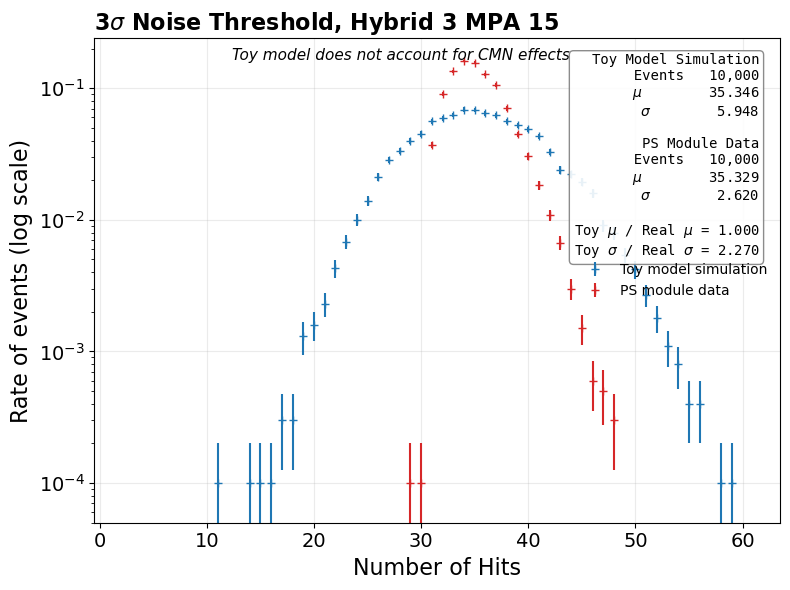

{'toy_mean': 35.3462, 'toy_std': 5.948205238557257, 'real_mean': 35.3286, 'real_std': 2.6202713676258798, 'ratio_mu': 1.0004981799448607, 'ratio_sigma': 2.270072219255169}


In [35]:
# --- Toy model WITHOUT common mode noise (plain Poisson -- the n -> infinity limit of a
# Negative Binomial, i.e. zero common-mode contribution) ---
hits_noCM = rng.poisson(real_mean, size=N_TOY)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"MPA {MPA_ID}",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


[Mixture] w = 0.3240, mean1 = 34.8973, n1 = 1.64e+12, mean2 = 34.8970, n2 = 1.66e+11, chi-square = 7735.0371
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0002_fig1.pdf


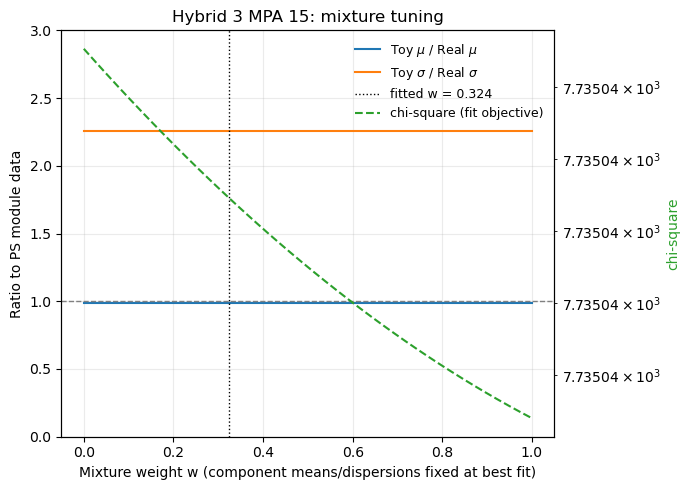

In [36]:
# --- Fit a 2-component Negative Binomial mixture directly to the PS module data ---
# w, mean1, n1, mean2, n2 are fit jointly (grid-seeded Nelder-Mead) against the real histogram,
# using the closed-form mixture pmf/sf -- no toy Monte Carlo simulation. Generalizes ZINB by
# giving the "extra" population a full second NBD shape instead of only a zero-spike (see
# fit_nbd_mixture's docstring for why this was needed and how reliability was confirmed).
w_best, mean1_best, n1_best, mean2_best, n2_best, chi2_best, max_bin_fit = fit_nbd_mixture(real_bins)
print(f"[Mixture] w = {w_best:.4f}, mean1 = {mean1_best:.4f}, n1 = {n1_best:.4g}, "
      f"mean2 = {mean2_best:.4f}, n2 = {n2_best:.4g}, chi-square = {chi2_best:.4f}")

mean_total, std_total = mixture_stats(w_best, mean1_best, n1_best, mean2_best, n2_best)

# Diagnostic: how chi-square and the std ratio move as the mixture weight w varies (component
# means/dispersions held fixed at their best-fit values) -- same purpose as the n/theta scans used
# elsewhere.
w_scan, chi2_scan, ratio_sigma_scan = mixture_chi2_scan(real_bins, mean1_best, n1_best, mean2_best, n2_best, max_bin_fit)
ratio_mu_curve = np.full_like(w_scan, mean_total / real_mean)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(w_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(w_scan, ratio_sigma_scan, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(w_best, color="black", linestyle=":", linewidth=1, label=f"fitted w = {w_best:.3f}")
ax.set_ylim(0, 3)
ax.set_xlabel("Mixture weight w (component means/dispersions fixed at best fit)")
ax.set_ylabel("Ratio to PS module data")
ax.set_title(rf"{HYBRID_NAME.replace('_', ' ')} MPA {MPA_ID}: mixture tuning")

ax2 = ax.twinx()
ax2.plot(w_scan, chi2_scan, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper right", fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0003_fig1.pdf


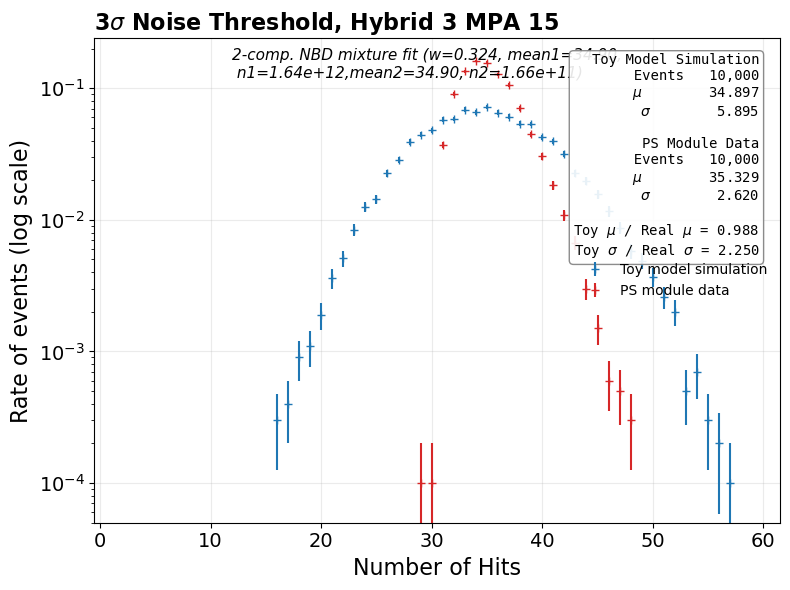

{'toy_mean': 34.8967, 'toy_std': 5.8946949971987515, 'real_mean': 35.3286, 'real_std': 2.6202713676258798, 'ratio_mu': 0.9877747773758372, 'ratio_sigma': 2.249650578191713}


In [37]:
# --- Toy model WITH 2-component Negative Binomial mixture fit ---
p1_best = n1_best / (n1_best + mean1_best)
p2_best = n2_best / (n2_best + mean2_best)
is_comp1 = rng.random(N_TOY) < w_best
hits_CM = np.where(is_comp1, rng.negative_binomial(n1_best, p1_best, size=N_TOY),
                    rng.negative_binomial(n2_best, p2_best, size=N_TOY))
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"MPA {MPA_ID}",
    f"2-comp. NBD mixture fit (w={w_best:.3f}, mean1={mean1_best:.2f}, \n n1={n1_best:.3g},"
    f"mean2={mean2_best:.2f}, n2={n2_best:.3g})",
)
print(stats_CM)


In [38]:
# Hybrid-level 3σ occupancy study

In [39]:
# The single-CM (Gaussian common-mode) model is replaced here by a direct Negative Binomial fit
# -- see investigation note above: pixel hit-count distributions are over-dispersed (Fano factor
# well above 1) in a way a single Gaussian common-mode term cannot reach, and the Monte-Carlo
# graded-burst alternative that COULD reach it was numerically unreliable at this scale. Negative
# Binomial is the natural closed-form distribution for this over-dispersion (a Poisson process
# whose rate is itself Gamma-modulated event-to-event -- the same idea as graded-burst, without
# the simulation instability, and much cheaper since no per-pixel Monte Carlo array is needed).
root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_toy, OG_NAME, HYBRID_NAME, HYBRID_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"Hybrid: {OG_NAME}/{HYBRID_NAME}, threshold = {N_SIGMA}-sigma")
print(f"Per-pixel noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_pixels = {len(sigma_i)})")
print(f"PS module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")
print(f"Fano factor (real_std^2 / real_mean) = {real_std ** 2 / real_mean:.3f} (>1 = over-dispersed relative to Poisson)")

N_TOY = 10_000
rng = np.random.default_rng(2026)


Hybrid: OpticalGroup_1/Hybrid_3, threshold = 3.0-sigma
Per-pixel noise sigma_i: mean = 2.2338, std = 0.2706 (n_pixels = 15360)
PS module data: n_events = 10000, mean hits/event = 82.1104, std = 16.8276
Fano factor (real_std^2 / real_mean) = 3.449 (>1 = over-dispersed relative to Poisson)


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0004_fig1.pdf


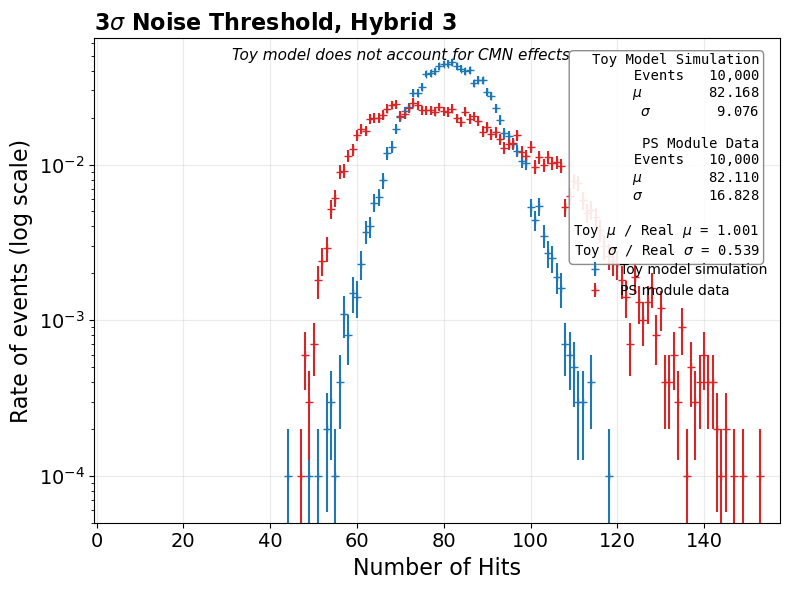

{'toy_mean': 82.1676, 'toy_std': 9.075853141165299, 'real_mean': 82.1104, 'real_std': 16.82760267655497, 'ratio_mu': 1.0006966230830685, 'ratio_sigma': 0.5393432038783644}


In [40]:
# --- Toy model WITHOUT common mode noise (plain Poisson -- the n -> infinity limit of a
# Negative Binomial, i.e. zero common-mode contribution) ---
hits_noCM = rng.poisson(real_mean, size=N_TOY)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


[Mixture] w = 0.3322, mean1 = 68.1373, n1 = 1.123e+11, mean2 = 89.1758, n2 = 48, chi-square = 182.7765
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0005_fig1.pdf


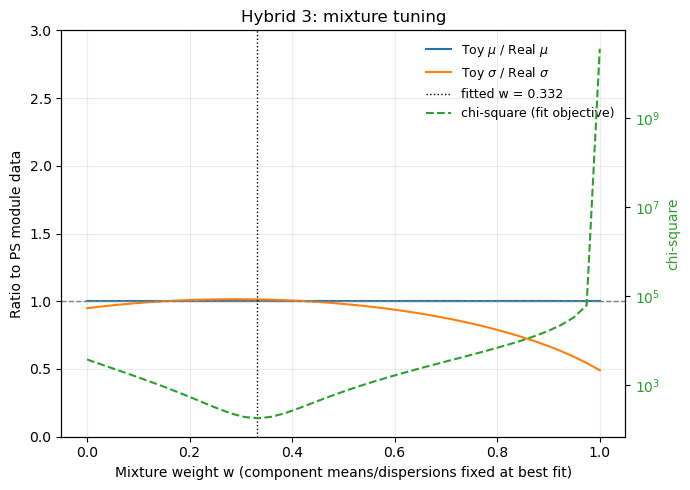

In [41]:
# --- Fit a 2-component Negative Binomial mixture directly to the PS module data ---
w_best, mean1_best, n1_best, mean2_best, n2_best, chi2_best, max_bin_fit = fit_nbd_mixture(real_bins)
print(f"[Mixture] w = {w_best:.4f}, mean1 = {mean1_best:.4f}, n1 = {n1_best:.4g}, "
      f"mean2 = {mean2_best:.4f}, n2 = {n2_best:.4g}, chi-square = {chi2_best:.4f}")

mean_total, std_total = mixture_stats(w_best, mean1_best, n1_best, mean2_best, n2_best)

w_scan, chi2_scan, ratio_sigma_scan = mixture_chi2_scan(real_bins, mean1_best, n1_best, mean2_best, n2_best, max_bin_fit)
ratio_mu_curve = np.full_like(w_scan, mean_total / real_mean)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(w_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(w_scan, ratio_sigma_scan, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(w_best, color="black", linestyle=":", linewidth=1, label=f"fitted w = {w_best:.3f}")
ax.set_ylim(0, 3)
ax.set_xlabel("Mixture weight w (component means/dispersions fixed at best fit)")
ax.set_ylabel("Ratio to PS module data")
ax.set_title(rf"{HYBRID_NAME.replace('_', ' ')}: mixture tuning")

ax2 = ax.twinx()
ax2.plot(w_scan, chi2_scan, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper right", fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0006_fig1.pdf


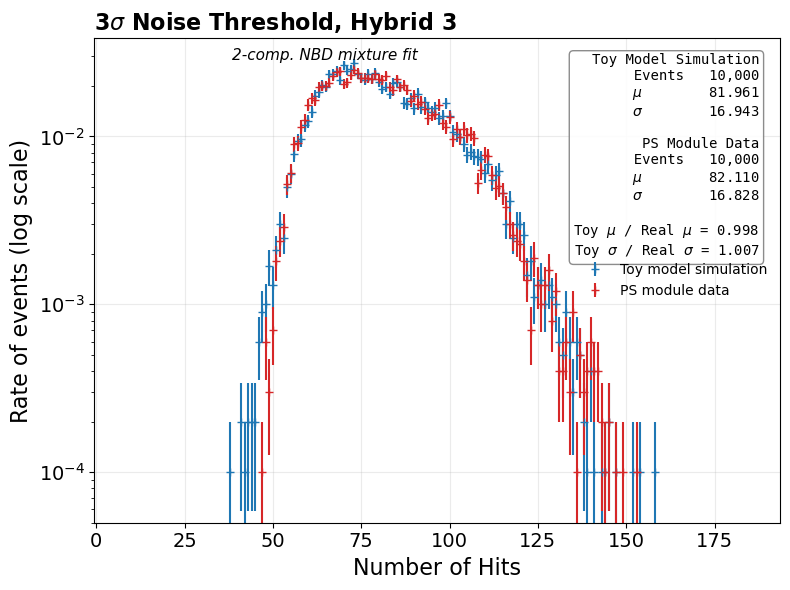

{'toy_mean': 81.9608, 'toy_std': 16.943130270407533, 'real_mean': 82.1104, 'real_std': 16.82760267655497, 'ratio_mu': 0.9981780627058205, 'ratio_sigma': 1.0068653625874777}


In [42]:
# --- Toy model WITH 2-component Negative Binomial mixture fit ---
p1_best = n1_best / (n1_best + mean1_best)
p2_best = n2_best / (n2_best + mean2_best)
is_comp1 = rng.random(N_TOY) < w_best
hits_CM = np.where(is_comp1, rng.negative_binomial(n1_best, p1_best, size=N_TOY),
                    rng.negative_binomial(n2_best, p2_best, size=N_TOY))
wide_max_bin = min(int(1.2 * (max(int(np.nonzero(real_bins)[0].max()), int(hits_CM.max())) + 3)), 400)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, HYBRID_NAME.replace("_", " "), f"",
    f"2-comp. NBD mixture fit",
    max_bin=wide_max_bin,
)
print(stats_CM)


In [43]:
# Module-level 3σ occupancy study

In [44]:

# Like at hybrid level, the single-CM (Gaussian common-mode) model is replaced here by a direct
# Negative Binomial fit -- see investigation note above.

root_file_toy = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
sigma_i, real_bins = extract_module_noise_and_hits(root_file_toy, OG_NAME, OG_ID, N_SIGMA)

n_events_real = int(round(real_bins.sum()))
idx = np.arange(len(real_bins))
real_mean = float(np.sum(idx * real_bins) / n_events_real)
real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

print(f"Module: {OG_TO_MODULE[OG_ID]}, threshold = {N_SIGMA}-sigma")
print(f"Per-pixel noise sigma_i: mean = {sigma_i.mean():.4f}, std = {sigma_i.std():.4f} (n_pixels = {len(sigma_i)})")
print(f"PS module data: n_events = {n_events_real}, mean hits/event = {real_mean:.4f}, std = {real_std:.4f}")
print(f"Fano factor (real_std^2 / real_mean) = {real_std ** 2 / real_mean:.3f} (>1 = over-dispersed relative to Poisson)")

N_TOY = 10_000
rng = np.random.default_rng(2026)


Module: 2, threshold = 3.0-sigma
Per-pixel noise sigma_i: mean = 2.2398, std = 0.2699 (n_pixels = 30720)
PS module data: n_events = 10000, mean hits/event = 114.8827, std = 16.5455
Fano factor (real_std^2 / real_mean) = 2.383 (>1 = over-dispersed relative to Poisson)


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0007_fig1.pdf


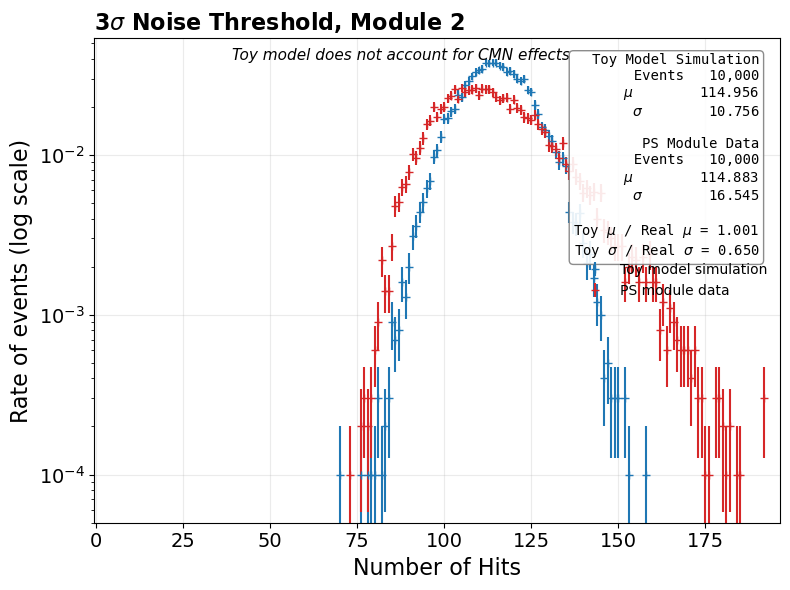

{'toy_mean': 114.9558, 'toy_std': 10.75598653587852, 'real_mean': 114.8827, 'real_std': 16.545493063369253, 'ratio_mu': 1.0006363012011381, 'ratio_sigma': 0.6500855849192939}


In [45]:
# --- Toy model WITHOUT common mode noise (plain Poisson -- the n -> infinity limit of a
# Negative Binomial, i.e. zero common-mode contribution) ---
hits_noCM = rng.poisson(real_mean, size=N_TOY)
stats_noCM = plot_toy_vs_data(
    hits_noCM, real_bins, N_SIGMA, f"Module {OG_TO_MODULE[OG_ID]}", f"",
    "Toy model does not account for CMN effects",
)
print(stats_noCM)


[Mixture] w = 0.6315, mean1 = 108.3883, n1 = 363.7, mean2 = 126.2962, n2 = 77.45, chi-square = 164.1320
Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0008_fig1.pdf


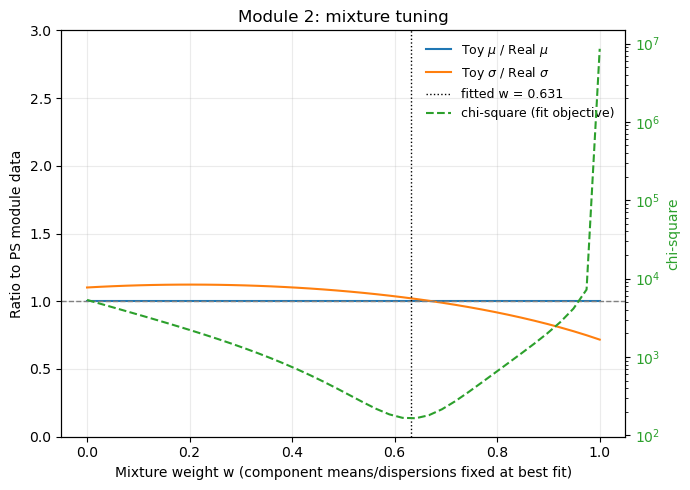

In [46]:
# --- Fit a 2-component Negative Binomial mixture directly to the PS module data ---
w_best, mean1_best, n1_best, mean2_best, n2_best, chi2_best, max_bin_fit = fit_nbd_mixture(real_bins)
print(f"[Mixture] w = {w_best:.4f}, mean1 = {mean1_best:.4f}, n1 = {n1_best:.4g}, "
      f"mean2 = {mean2_best:.4f}, n2 = {n2_best:.4g}, chi-square = {chi2_best:.4f}")

mean_total, std_total = mixture_stats(w_best, mean1_best, n1_best, mean2_best, n2_best)

w_scan, chi2_scan, ratio_sigma_scan = mixture_chi2_scan(real_bins, mean1_best, n1_best, mean2_best, n2_best, max_bin_fit)
ratio_mu_curve = np.full_like(w_scan, mean_total / real_mean)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(w_scan, ratio_mu_curve, label=r"Toy $\mu$ / Real $\mu$", color="tab:blue")
ax.plot(w_scan, ratio_sigma_scan, label=r"Toy $\sigma$ / Real $\sigma$", color="tab:orange")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.axvline(w_best, color="black", linestyle=":", linewidth=1, label=f"fitted w = {w_best:.3f}")
ax.set_ylim(0, 3)
ax.set_xlabel("Mixture weight w (component means/dispersions fixed at best fit)")
ax.set_ylabel("Ratio to PS module data")
ax.set_title(rf"Module {OG_TO_MODULE[OG_ID]}: mixture tuning")

ax2 = ax.twinx()
ax2.plot(w_scan, chi2_scan, label="chi-square (fit objective)", color="tab:green", linestyle="--")
ax2.set_yscale("log")
ax2.set_ylabel("chi-square", color="tab:green")
ax2.tick_params(axis="y", labelcolor="tab:green")

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper right", fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Saved figure to /home/luc1010lucas/Thesis/TrackerHistos_12_lucas/figs/figure_0009_fig1.pdf


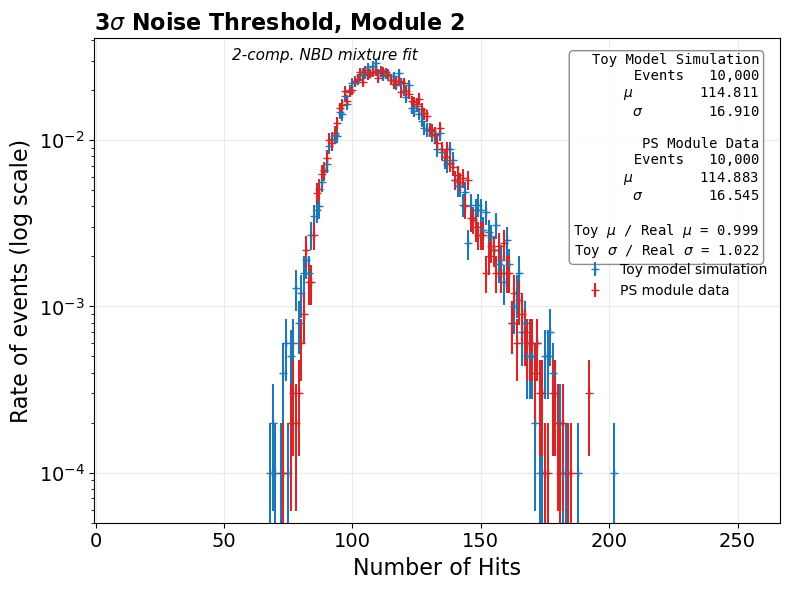

{'toy_mean': 114.8111, 'toy_std': 16.91042331788297, 'real_mean': 114.8827, 'real_std': 16.545493063369253, 'ratio_mu': 0.9993767555950548, 'ratio_sigma': 1.022056172827007}


In [47]:
# --- Toy model WITH 2-component Negative Binomial mixture fit ---
p1_best = n1_best / (n1_best + mean1_best)
p2_best = n2_best / (n2_best + mean2_best)
is_comp1 = rng.random(N_TOY) < w_best
hits_CM = np.where(is_comp1, rng.negative_binomial(n1_best, p1_best, size=N_TOY),
                    rng.negative_binomial(n2_best, p2_best, size=N_TOY))
# Extra x-axis padding for THIS plot only: the default max_bin (tight around the data's own
# tail) leaves the legend (loc="center right") overlapping the high-hit-count tail points here.
# Widen just this call's max_bin instead of touching plot_toy_vs_data or any other call.
wide_max_bin = min(int(1.3 * (max(int(np.nonzero(real_bins)[0].max()), int(hits_CM.max())) + 3)), 400)
stats_CM = plot_toy_vs_data(
    hits_CM, real_bins, N_SIGMA, f"Module {OG_TO_MODULE[OG_ID]}", f"",
    f"2-comp. NBD mixture fit",
    max_bin=wide_max_bin,
)
print(stats_CM)


In [48]:
# --- Summary table: ZINB fit results across all 8 MPAs of Hybrid_...---

In [49]:
import pandas as pd

mpa_specs = list(range(8, 16))  # MPA_8 .. MPA_15 of Hybrid_...

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")

# fit_nbd_mixture is a strict generalization of plain NBD (each component collapses back toward
# the single-NBD fit when a second population is not needed) -- see its docstring and the
# investigation note at the start of this section.

rows = []
for mpa_id in mpa_specs:
    sigma_i, real_bins = extract_MPA_noise_and_hits(root_file_summary, OG_NAME, HYBRID_NAME, HYBRID_ID, mpa_id, N_SIGMA)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    w_best, mean1_best, n1_best, mean2_best, n2_best, chi2_best, max_bin_fit = fit_nbd_mixture(real_bins)
    mean_total, std_total = mixture_stats(w_best, mean1_best, n1_best, mean2_best, n2_best)

    ratio_mu = mean_total / real_mean
    ratio_sigma = std_total / real_std

    rows.append({
        "MPA": mpa_id,
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-pixel)": sigma_i.mean(),
        "Fano": real_std ** 2 / real_mean,
        "w": w_best,
        "mean₁": mean1_best,
        "n₁": n1_best,
        "mean₂": mean2_best,
        "n₂": n2_best,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"MPA_{mpa_id}: w={w_best:.4f}, mean1={mean1_best:.2f}, n1={n1_best:.3g}, mean2={mean2_best:.2f}, "
          f"n2={n2_best:.3g}, chi2={chi2_best:.1f}, ratio_mu={ratio_mu:.3f}, ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-pixel)": 2, "Fano": 2, "p_dead": 5, "NBD n": 3,
    "w": 4, "mean₁": 2, "n₁": 3, "mean₂": 2, "n₂": 3, "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display


MPA_8: w=0.9972, mean1=5.92, n1=6.7e+10, mean2=28.04, n2=19.3, chi2=2776.6, ratio_mu=0.964, ratio_sigma=1.384
MPA_9: w=0.9678, mean1=5.11, n1=5.19, mean2=13.45, n2=2.78, chi2=44.3, ratio_mu=1.007, ratio_sigma=1.040
MPA_10: w=0.8550, mean1=6.64, n1=26.2, mean2=12.00, n2=5.57, chi2=300.9, ratio_mu=1.000, ratio_sigma=1.037
MPA_11: w=0.9996, mean1=6.79, n1=1.25e+11, mean2=25.12, n2=1.89e+10, chi2=1882.8, ratio_mu=0.982, ratio_sigma=1.395
MPA_12: w=0.9811, mean1=1.82, n1=4.25e+10, mean2=6.51, n2=2.32, chi2=484.3, ratio_mu=0.996, ratio_sigma=1.097
MPA_13: w=0.7371, mean1=13.24, n1=7.33, mean2=29.63, n2=2.26e+11, chi2=852.0, ratio_mu=1.029, ratio_sigma=1.056
MPA_14: w=0.9703, mean1=1.71, n1=2.3e+10, mean2=7.20, n2=1.6, chi2=1836.3, ratio_mu=0.977, ratio_sigma=1.268
MPA_15: w=0.3240, mean1=34.90, n1=1.64e+12, mean2=34.90, n2=1.66e+11, chi2=7735.0, ratio_mu=0.988, ratio_sigma=2.254


,MPA,Real mean,Real σ,σ_i (per-pixel),Fano,w,mean₁,n₁,mean₂,n₂,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,8,6.21,1.98,2.34,0.63,0.9972,5.92,6.701374e+10,28.04,1.929200e+01,2777,0.96,1.38
1,9,5.33,3.66,2.20,2.51,0.9678,5.11,5.193000e+00,13.45,2.784000e+00,44,1.01,1.04
2,10,7.42,3.87,2.28,2.02,0.8550,6.64,2.615700e+01,12.00,5.574000e+00,301,1.00,1.04
3,11,6.93,1.89,2.33,0.51,0.9996,6.79,1.247199e+11,25.12,1.892861e+10,1883,0.98,1.40
4,12,1.91,1.49,2.27,1.15,0.9811,1.82,4.251300e+10,6.51,2.320000e+00,484,1.00,1.10
5,13,17.06,8.84,2.20,4.58,0.7371,13.24,7.331000e+00,29.63,2.260493e+11,852,1.03,1.06
6,14,1.92,1.52,2.31,1.20,0.9703,1.71,2.300873e+10,7.20,1.604000e+00,1836,0.98,1.27
7,15,35.33,2.62,1.94,0.19,0.3240,34.90,1.639784e+12,34.90,1.660222e+11,7735,0.99,2.25


In [50]:
# --- Summary table: ZINB fit results across all 6 hybrids (pixel) ---

In [51]:
import pandas as pd

hybrid_specs = [
    ("OpticalGroup_0", "Hybrid_0", 0, "R"),
    ("OpticalGroup_1", "Hybrid_2", 2, "R"),
    ("OpticalGroup_7", "Hybrid_14", 14, "R"),
    ("OpticalGroup_0", "Hybrid_1", 1, "L"),
    ("OpticalGroup_1", "Hybrid_3", 3, "L"),
    ("OpticalGroup_7", "Hybrid_15", 15, "L"),
]

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")
N_SIGMA_SUMMARY = 3.0

# fit_nbd_mixture (2-component NBD mixture) replaces the earlier fit_zinb here -- it also
# properly captures Hybrid_15's genuine bimodality (see investigation note), and does so better
# (chi-square 4874 -> 1215) without needing an explicit zero-spike population at all.

rows = []
for og_name, hybrid_name, hybrid_id, side in hybrid_specs:
    sigma_i, real_bins = extract_hybrid_noise_and_hits(root_file_summary, og_name, hybrid_name, hybrid_id, N_SIGMA_SUMMARY)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    w_best, mean1_best, n1_best, mean2_best, n2_best, chi2_best, max_bin_fit = fit_nbd_mixture(real_bins)
    mean_total, std_total = mixture_stats(w_best, mean1_best, n1_best, mean2_best, n2_best)

    ratio_mu = mean_total / real_mean
    ratio_sigma = std_total / real_std

    rows.append({
        "Hybrid": hybrid_id,
        "Side": side,
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-pixel)": sigma_i.mean(),
        "Fano": real_std ** 2 / real_mean,
        "w": w_best,
        "mean₁": mean1_best,
        "n₁": n1_best,
        "mean₂": mean2_best,
        "n₂": n2_best,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"Hybrid {hybrid_id} ({side}): w={w_best:.4f}, mean1={mean1_best:.2f}, n1={n1_best:.3g}, "
          f"mean2={mean2_best:.2f}, n2={n2_best:.3g}, chi2={chi2_best:.1f}, ratio_mu={ratio_mu:.3f}, ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-pixel)": 2, "Fano": 2, "p_dead": 5, "NBD n": 3,
    "w": 4, "mean₁": 2, "n₁": 3, "mean₂": 2, "n₂": 3, "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display


Hybrid 0 (R): w=0.5747, mean1=29.71, n1=18, mean2=87.87, n2=4.63, chi2=1544.7, ratio_mu=1.083, ratio_sigma=1.185
Hybrid 2 (R): w=0.5835, mean1=22.78, n1=144, mean2=47.27, n2=5.91, chi2=328.1, ratio_mu=1.006, ratio_sigma=1.018
Hybrid 14 (R): w=0.5795, mean1=33.40, n1=140, mean2=66.65, n2=7.6, chi2=427.2, ratio_mu=1.005, ratio_sigma=1.025
Hybrid 1 (L): w=0.8964, mean1=51.84, n1=4.65, mean2=132.16, n2=3.67e+11, chi2=1390.4, ratio_mu=1.015, ratio_sigma=1.051
Hybrid 3 (L): w=0.3322, mean1=68.14, n1=1.12e+11, mean2=89.18, n2=48, chi2=182.8, ratio_mu=1.001, ratio_sigma=1.014
Hybrid 15 (L): w=0.0636, mean1=53.08, n1=1.32, mean2=94.58, n2=44.2, chi2=1215.4, ratio_mu=0.990, ratio_sigma=1.185


,Hybrid,Side,Real mean,Real σ,σ_i (per-pixel),Fano,w,mean₁,n₁,mean₂,n₂,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,0,R,50.25,33.96,2.30,22.95,0.5747,29.71,1.798200e+01,87.87,4.631000e+00,1545,1.08,1.18
1,2,R,32.77,18.07,2.25,9.97,0.5835,22.78,1.436620e+02,47.27,5.910000e+00,328,1.01,1.02
2,14,R,47.16,23.23,2.29,11.44,0.5795,33.40,1.397820e+02,66.65,7.599000e+00,427,1.00,1.03
3,1,L,59.26,32.63,2.24,17.97,0.8964,51.84,4.653000e+00,132.16,3.674628e+11,1390,1.02,1.05
4,3,L,82.11,16.83,2.23,3.45,0.3322,68.14,1.123075e+11,89.18,4.800400e+01,183,1.00,1.01
5,15,L,92.90,19.24,2.24,3.98,0.0636,53.08,1.321000e+00,94.58,4.417900e+01,1215,0.99,1.18


In [52]:
# --- Summary table: ZINB fit results across all 3 modules (pixel) ---

In [53]:
import pandas as pd

module_specs = [
    ("OpticalGroup_0", 0),
    ("OpticalGroup_1", 1),
    ("OpticalGroup_7", 7),
]
OG_TO_MODULE = {0: 1, 1: 2, 7: 4}

root_file_summary = ROOT.TFile.Open("/home/luc1010lucas/Thesis/TrackerHistos_12_lucas/TrackerHistos_10.root", "READ")

rows = []
for og_name, og_id in module_specs:
    sigma_i, real_bins = extract_module_noise_and_hits(root_file_summary, og_name, og_id, N_SIGMA)

    n_events_real = float(real_bins.sum())
    idx = np.arange(len(real_bins))
    real_mean = float(np.sum(idx * real_bins) / n_events_real)
    real_std = float(np.sqrt(np.sum(real_bins * (idx - real_mean) ** 2) / n_events_real))

    w_best, mean1_best, n1_best, mean2_best, n2_best, chi2_best, max_bin_fit = fit_nbd_mixture(real_bins)
    mean_total, std_total = mixture_stats(w_best, mean1_best, n1_best, mean2_best, n2_best)

    ratio_mu = mean_total / real_mean
    ratio_sigma = std_total / real_std

    rows.append({
        "Module": OG_TO_MODULE[og_id],
        "Real mean": real_mean,
        "Real σ": real_std,
        "σ_i (per-pixel)": sigma_i.mean(),
        "Fano": real_std ** 2 / real_mean,
        "w": w_best,
        "mean₁": mean1_best,
        "n₁": n1_best,
        "mean₂": mean2_best,
        "n₂": n2_best,
        "χ² best": chi2_best,
        "Toy μ/Real μ": ratio_mu,
        "Toy σ/Real σ": ratio_sigma,
    })
    print(f"Module {OG_TO_MODULE[og_id]}: w={w_best:.4f}, mean1={mean1_best:.2f}, n1={n1_best:.3g}, "
          f"mean2={mean2_best:.2f}, n2={n2_best:.3g}, chi2={chi2_best:.1f}, ratio_mu={ratio_mu:.3f}, ratio_sigma={ratio_sigma:.3f}")

df_summary = pd.DataFrame(rows)
df_summary_display = df_summary.round({
    "Real mean": 2, "Real σ": 2, "σ_i (per-pixel)": 2, "Fano": 2, "p_dead": 5, "NBD n": 3,
    "w": 4, "mean₁": 2, "n₁": 3, "mean₂": 2, "n₂": 3, "χ² best": 0, "Toy μ/Real μ": 2, "Toy σ/Real σ": 2,
})
df_summary_display["χ² best"] = df_summary_display["χ² best"].astype(int)
df_summary_display


Module 1: w=0.7039, mean1=93.18, n1=25.7, mean2=150.72, n2=109, chi2=604.3, ratio_mu=1.007, ratio_sigma=1.027
Module 2: w=0.6315, mean1=108.39, n1=364, mean2=126.30, n2=77.5, chi2=164.1, ratio_mu=1.001, ratio_sigma=1.022
Module 4: w=0.1051, mean1=138.42, n1=6.11, mean2=140.54, n2=99.7, chi2=644.8, ratio_mu=1.002, ratio_sigma=1.140


,Module,Real mean,Real σ,σ_i (per-pixel),Fano,w,mean₁,n₁,mean₂,n₂,χ² best,Toy μ/Real μ,Toy σ/Real σ
0,1,109.51,32.30,2.27,9.53,0.7039,93.18,25.713,150.72,109.275,604,1.01,1.03
1,2,114.88,16.55,2.24,2.38,0.6315,108.39,363.745,126.30,77.452,164,1.00,1.02
2,4,140.06,22.32,2.27,3.56,0.1051,138.42,6.106,140.54,99.729,645,1.00,1.14


In [54]:
# What "CMN" means now: each fit reports the fitted 2-component NBD mixture parameters directly
# (w, mean1, n1, mean2, n2) and the real data's model-independent Fano factor -- no derived scalar
# CMN metric. A CV_rate_eff (moment-matching the mixture's overall mean/variance to an equivalent
# single NBD's n) was tried and removed again: although exact (no linearization, unlike the
# earlier sigma_cm_equiv), it turned out to be nearly redundant with the Fano factor already
# reported (CV_rate_eff = sqrt((Fano-1)/mean), computable directly from real data with no fit at
# all), and -- more importantly -- two mixtures with identical mean/variance (hence identical
# CV_rate_eff) can have completely different shapes (checked directly: one near-unimodal, one
# genuinely two-humped with a dip exactly where the other peaks). Collapsing the fit back into one
# number throws away precisely the shape information the mixture model exists to capture, so the
# raw fitted parameters plus Fano are reported instead of another summary number.


# pros of closed form NBD over graded burst model : 
# - No sampling noise in the objective function
# ->No risk of the optimizer landing in an unphysical corner
# - Exact solution in closed form, not an approx
# - speed: no need to simulate a large number of events for each objective function evaluation 
# - reproducibility: no need to set a random seed for the optimizer to get the same result

### Strip/pixel common-mode correlation: an independent finding (not used in the toy models above)

The ROOT file also contains a direct measurement of the correlation between a hybrid's STRIP hit
count and its PIXEL hit count in the *same* real event
(`CommonNoiseStripPixelCorrelation_SigmaNoise_3.00_Hybrid(id)` and its
`_OccupancyDriven_` counterpart at a lower, more typical threshold). This was checked directly
across all 6 hybrids to see whether it could usefully inform either the strip or pixel toy models
above.

| Hybrid | side | $\rho$ at 3$\sigma$ (same threshold as the toy models) | $\rho$ at occupancy-driven (lower) threshold |
|---|---|---|---|
| 0 | R | 0.037 | 0.247 |
| 2 | R | 0.029 | 0.404 |
| 14 | R | 0.053 | 0.281 |
| 1 | L | 0.109 | 0.208 |
| 3 | L | 0.106 | 0.267 |
| 15 | L | 0.106 | 0.297 |

**Conclusion: not useful for the toy models above.** At the 3$\sigma$ threshold these models are
actually fit against, the strip/pixel correlation is weak (0.03-0.11, i.e. strip and pixel hit
counts on the same hybrid share at most ~1% of their variance, $\rho^2$). Whatever drives a rare,
extreme strip fluctuation and a rare, extreme pixel fluctuation on the same hybrid are, at this
operating point, largely independent -- building this correlation into a joint strip+pixel
generative model (the same way cross-hybrid $\rho$ was built into the strip module model) would
add real complexity for a small effect, and was not pursued.

Two things about the numbers themselves are worth recording as independent observations, separate
from the toy-model question:
- **The correlation is 3-8x stronger at the occupancy-driven (lower, more typical) threshold**
  than at 3$\sigma$ (e.g. Hybrid_2: 0.029 $\to$ 0.404). A genuine shared driver (power supply,
  temperature, or similar) plausibly has more room to show up across many typical events; at the
  rare 3$\sigma$ tail, events are likely dominated by threshold-specific, ASIC-specific
  idiosyncrasies (different amplification chains for strips vs. pixels) that dilute the shared
  signal.
- **L hybrids consistently show higher 3$\sigma$ correlation than R hybrids** (0.106-0.109 vs.
  0.029-0.053) -- yet another instance of the same R/L asymmetry documented throughout this
  investigation (effective threshold correction, common-mode amplitude, and now this).